In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Output: /kaggle/working/veremi_eda_outputs
Dataset directory: /kaggle/input/datasets/kabil08/vanet-ds
Scenario sources found: 19


,archive,layout,size_mb
0,ConstPosOffset_1416,extracted_folder,574.481575
1,ConstPos_1416,extracted_folder,574.595976
2,ConstSpeedOffset_1416,extracted_folder,574.018081
3,ConstSpeed_1416,extracted_folder,574.056933
4,DataReplaySybil_1416,extracted_folder,575.095997
5,DataReplay_1416,extracted_folder,574.730469
6,DelayedMessages_1416,extracted_folder,544.726529
7,Disruptive_1416,extracted_folder,575.008368
8,DoSDisruptiveSybil_1416,extracted_folder,729.520042
9,DoSDisruptive_1416,extracted_folder,872.366213


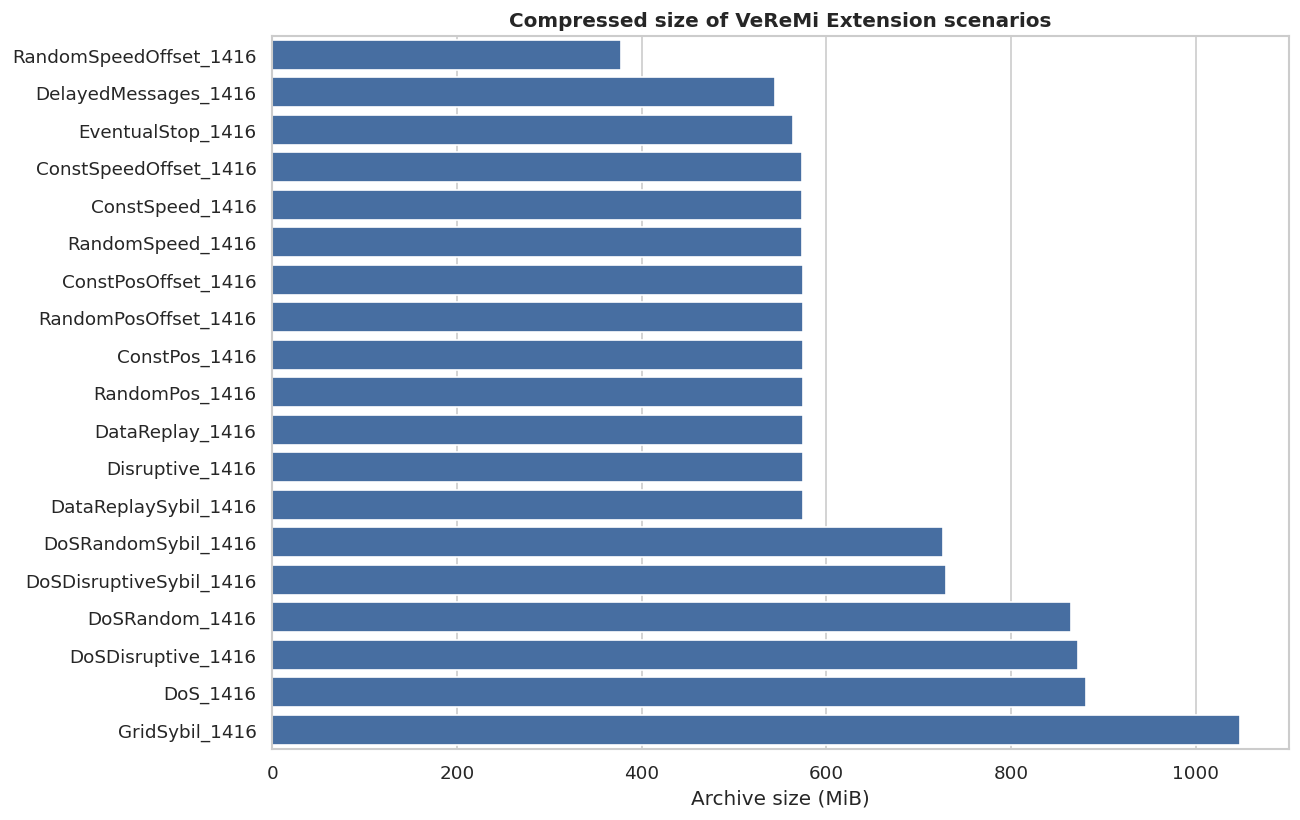

Parser ready.
[01/19] ConstPosOffset_1416
[02/19] ConstPos_1416
[03/19] ConstSpeedOffset_1416
[04/19] ConstSpeed_1416
[05/19] DataReplaySybil_1416
[06/19] DataReplay_1416
[07/19] DelayedMessages_1416
[08/19] Disruptive_1416
[09/19] DoSDisruptiveSybil_1416
[10/19] DoSDisruptive_1416
[11/19] DoSRandomSybil_1416
[12/19] DoSRandom_1416
[13/19] DoS_1416
[14/19] EventualStop_1416
[15/19] GridSybil_1416
[16/19] RandomPosOffset_1416
[17/19] RandomPos_1416
[18/19] RandomSpeedOffset_1416
[19/19] RandomSpeed_1416
Processed 11,649,834 received messages; saved 190,000 sampled rows.


,scenario,period,rows,benign,malicious,malicious_percent,unique_senders,unique_receivers,truth_missing
0,ConstPos,1416,534424,367726,166698,31.192087,1019,1003,1981
1,ConstPosOffset,1416,534424,367726,166698,31.192087,1019,1003,1981
2,ConstSpeed,1416,534424,367726,166698,31.192087,1019,1003,1981
3,ConstSpeedOffset,1416,534424,367726,166698,31.192087,1019,1003,1981
4,DataReplay,1416,534424,367726,166698,31.192087,1019,1003,1981
5,DataReplaySybil,1416,534424,367726,166698,31.192087,1019,1003,1981
6,DelayedMessages,1416,534424,367726,166698,31.192087,1019,1003,1981
7,Disruptive,1416,534424,367726,166698,31.192087,1019,1003,1981
8,DoS,1416,866097,369701,496396,57.314135,1019,1003,3968
9,DoSDisruptive,1416,851630,369364,482266,56.628583,1019,1003,3605


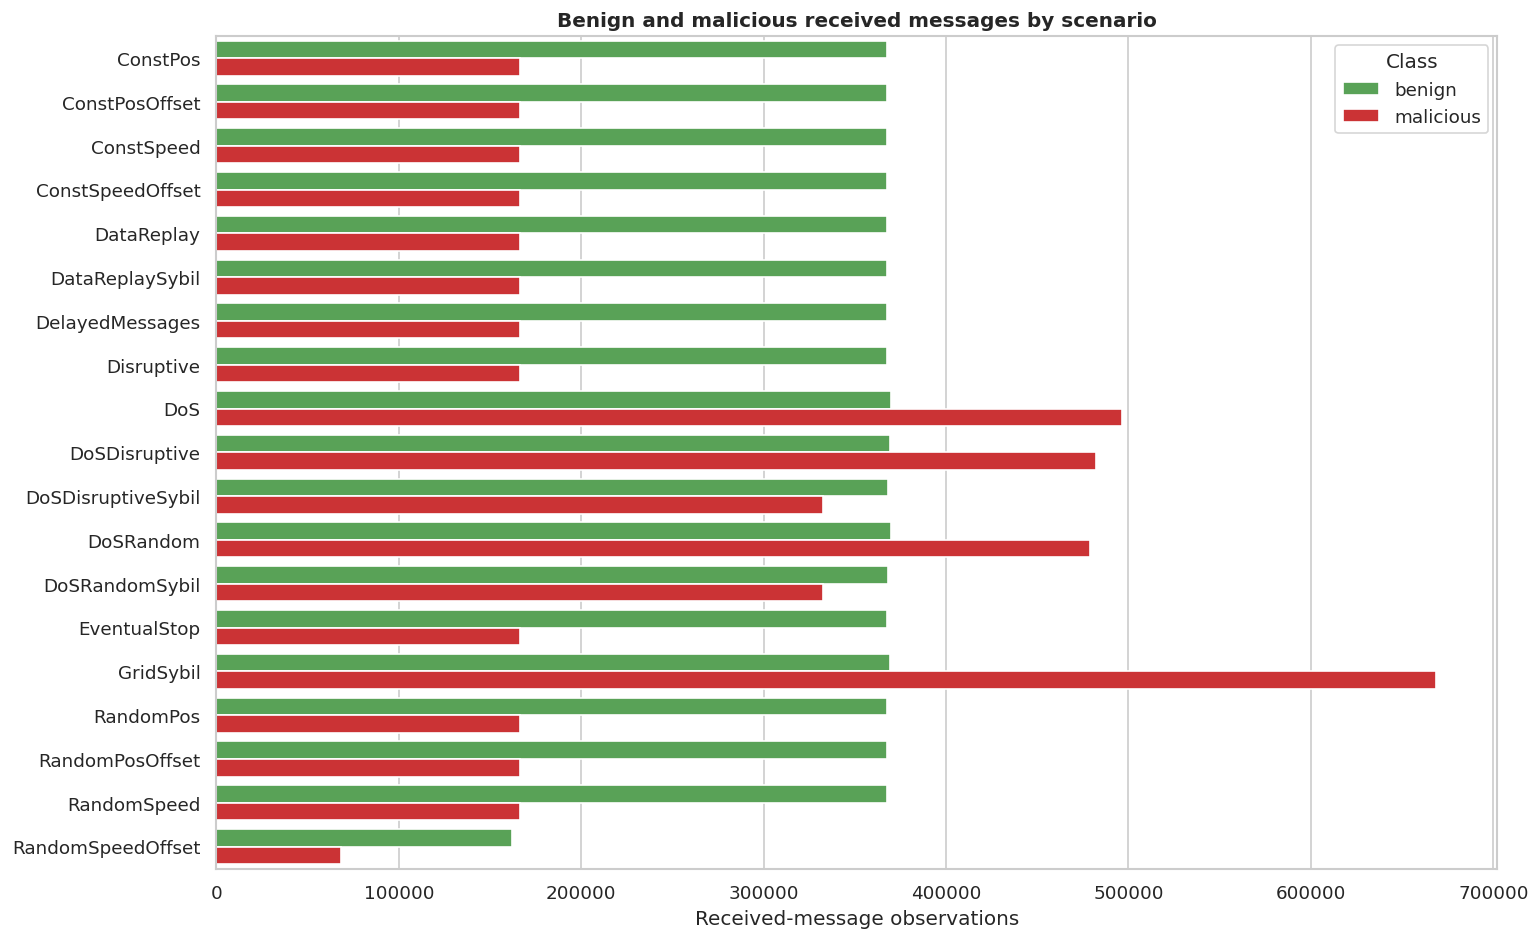

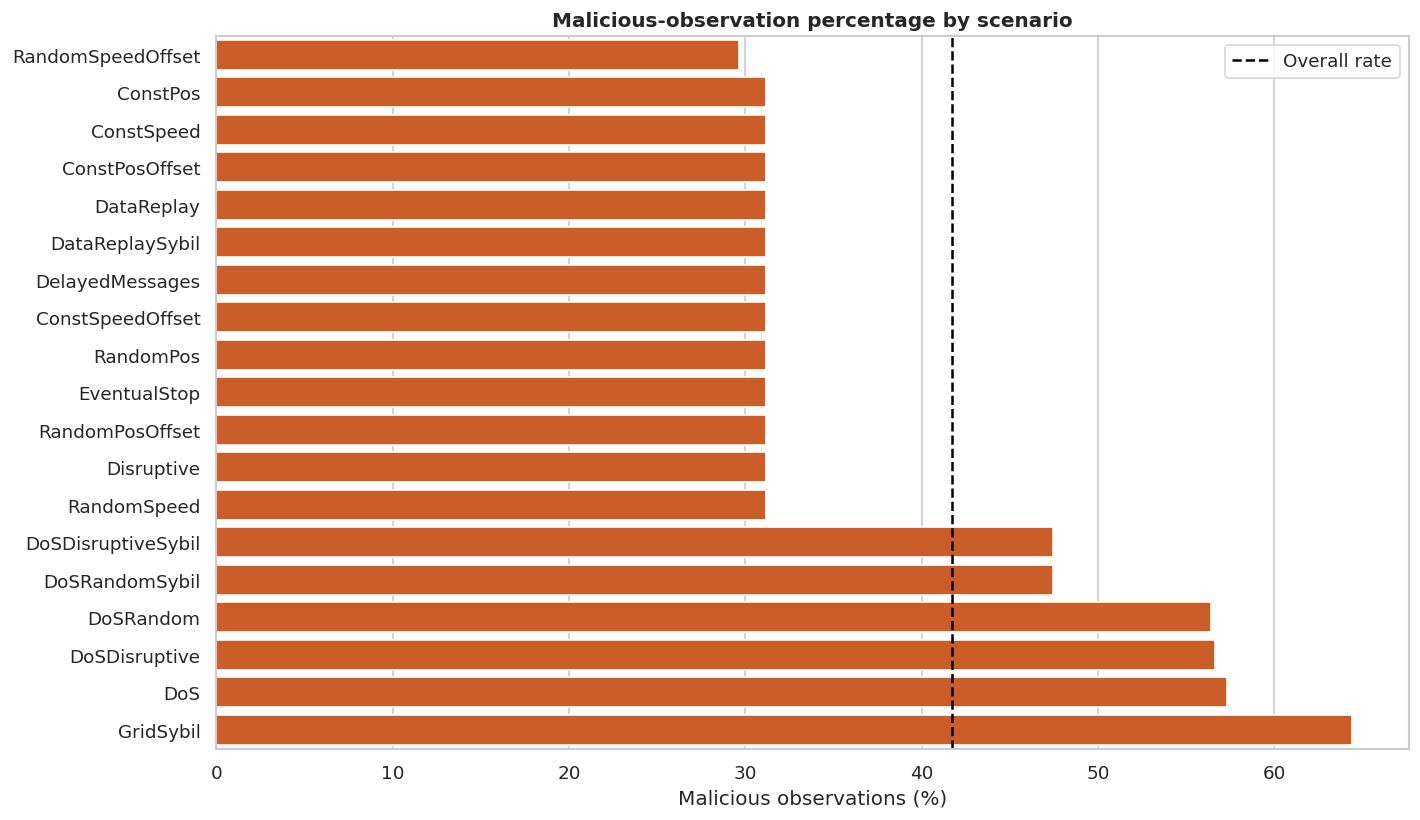

,feature,missing_percent
0,audit_heading_error,0.367368
1,audit_position_error,0.367368
2,audit_speed_error,0.367368
3,audit_accel_error,0.367368


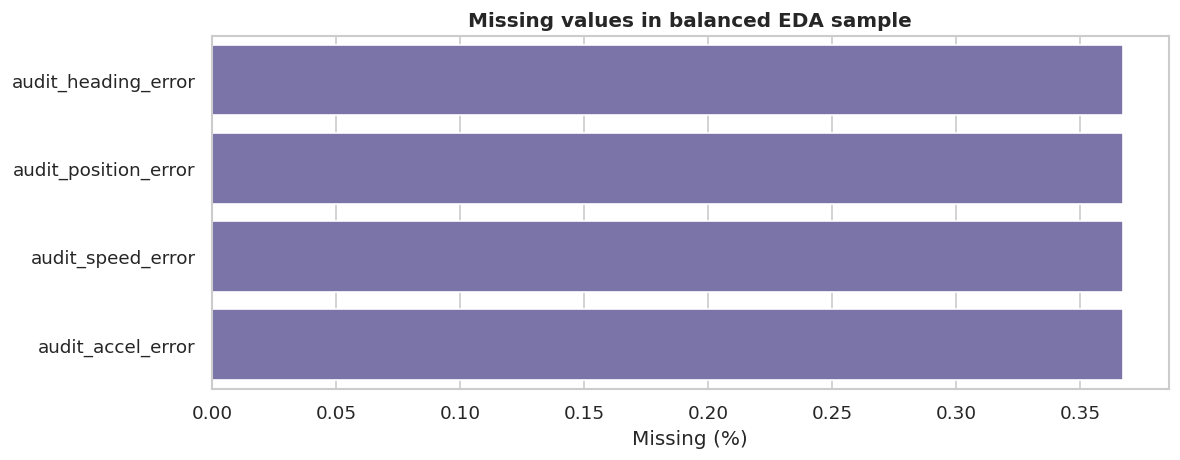

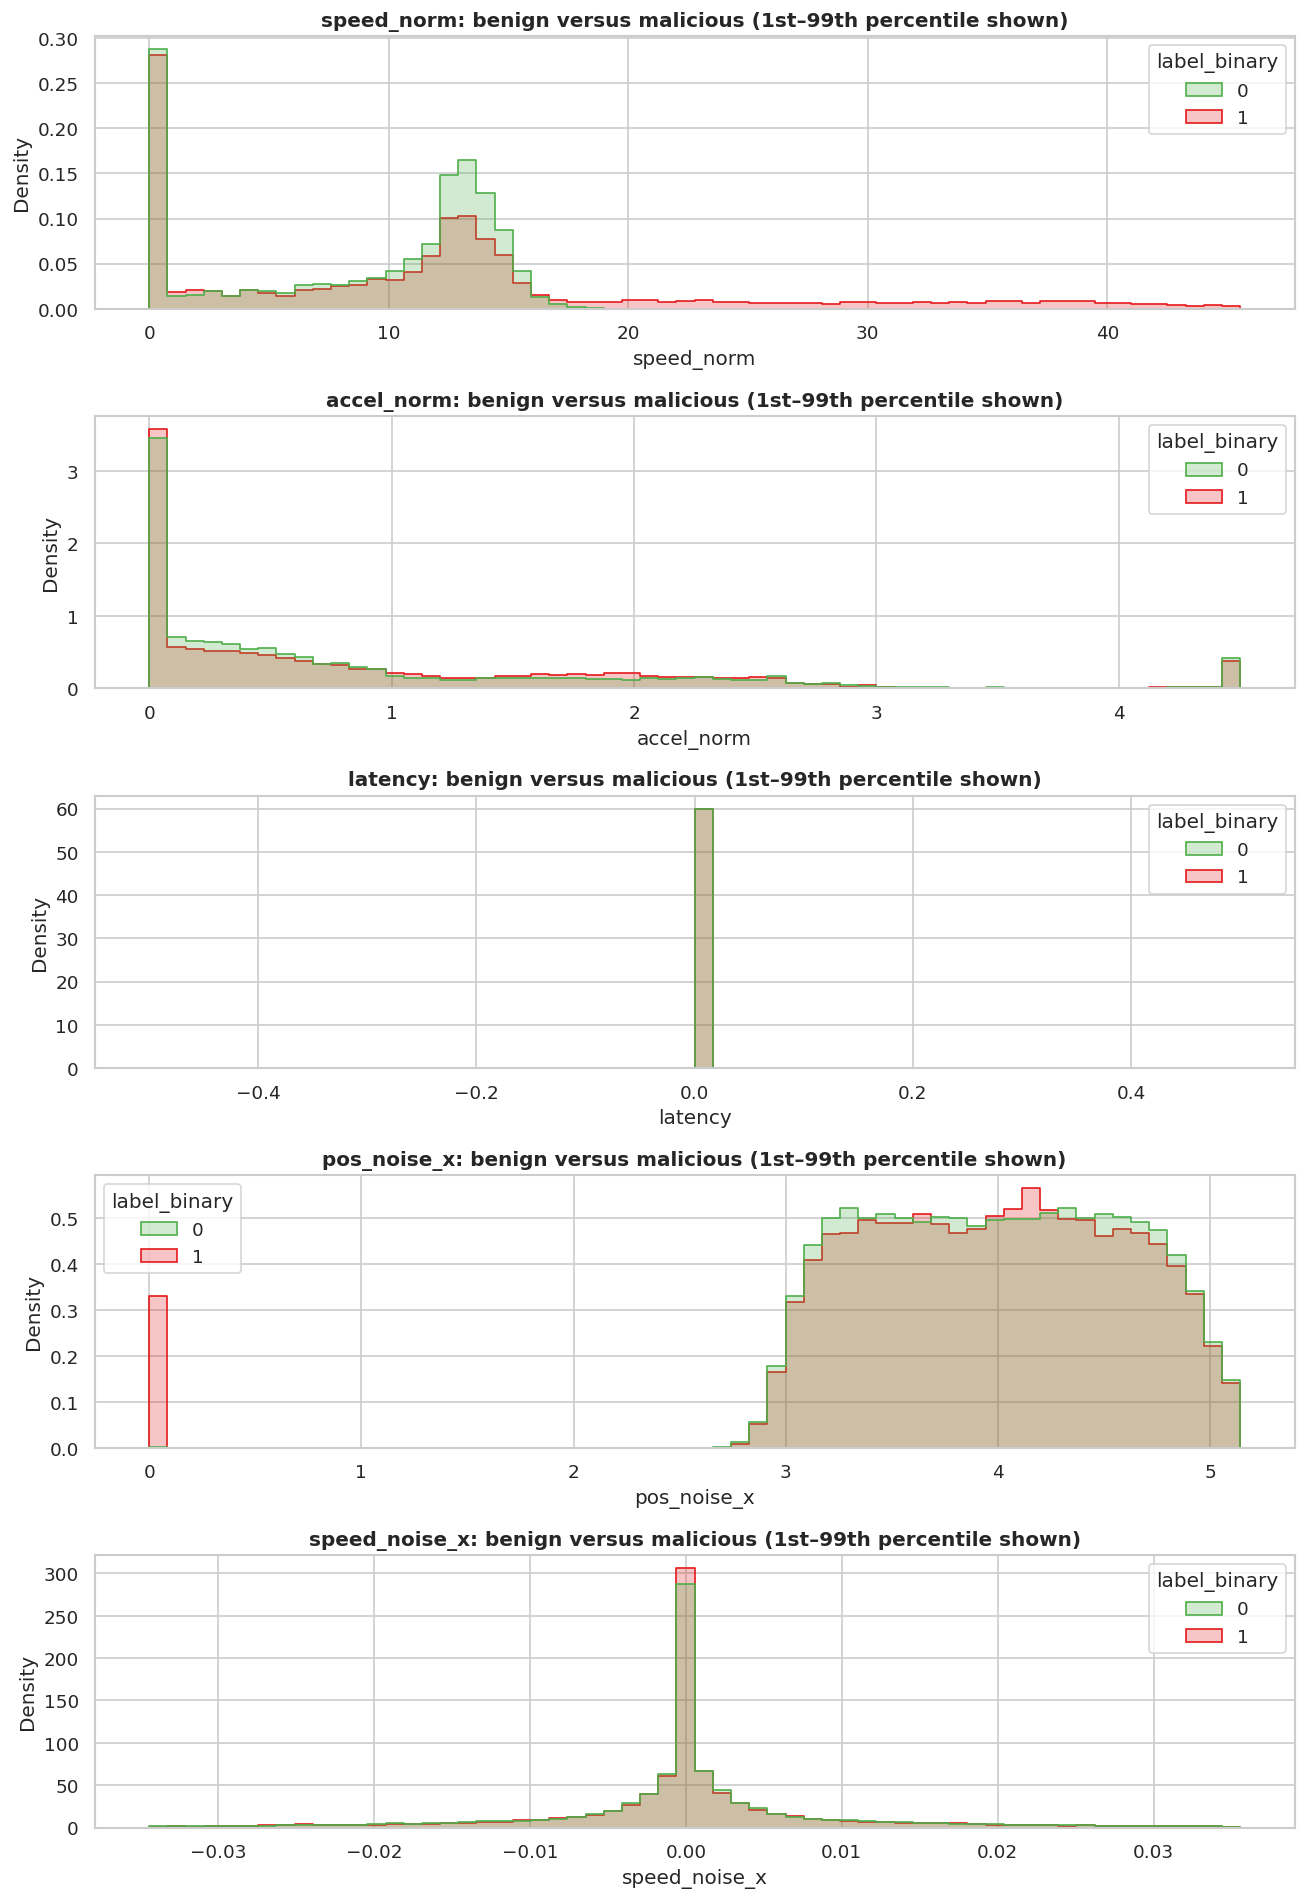

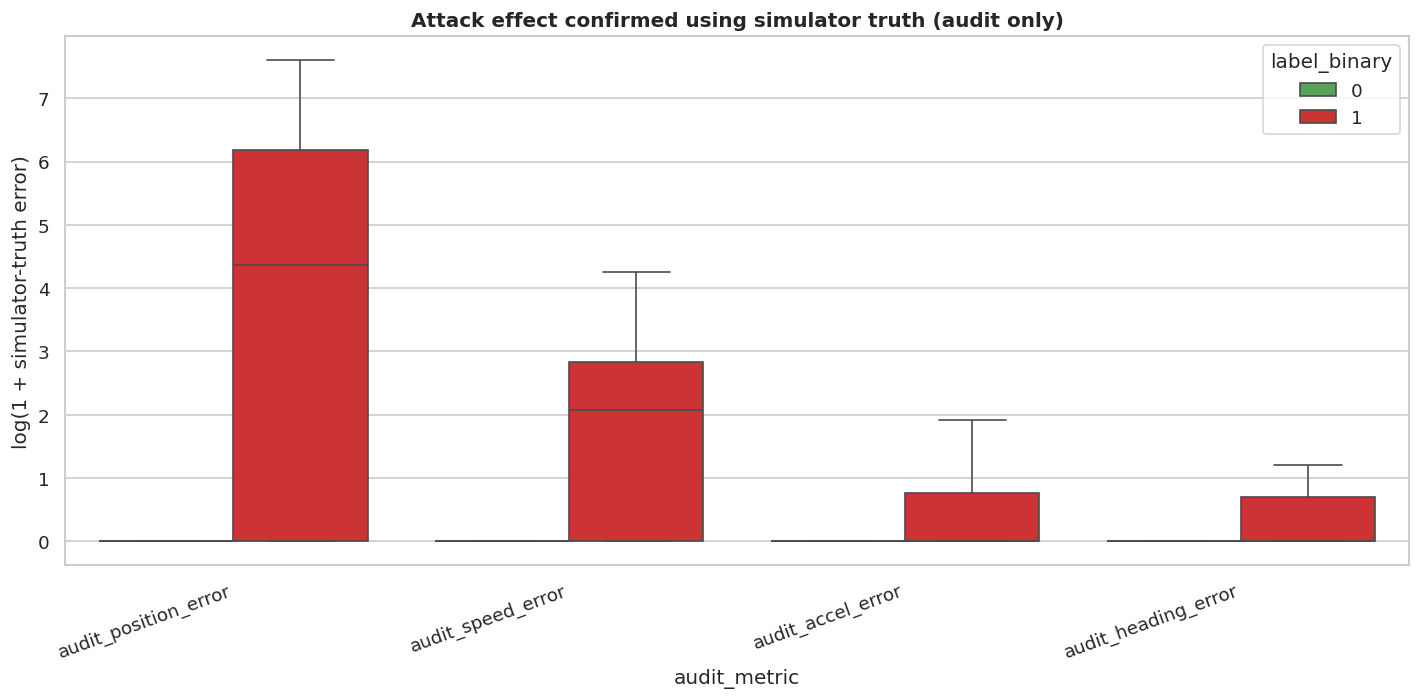

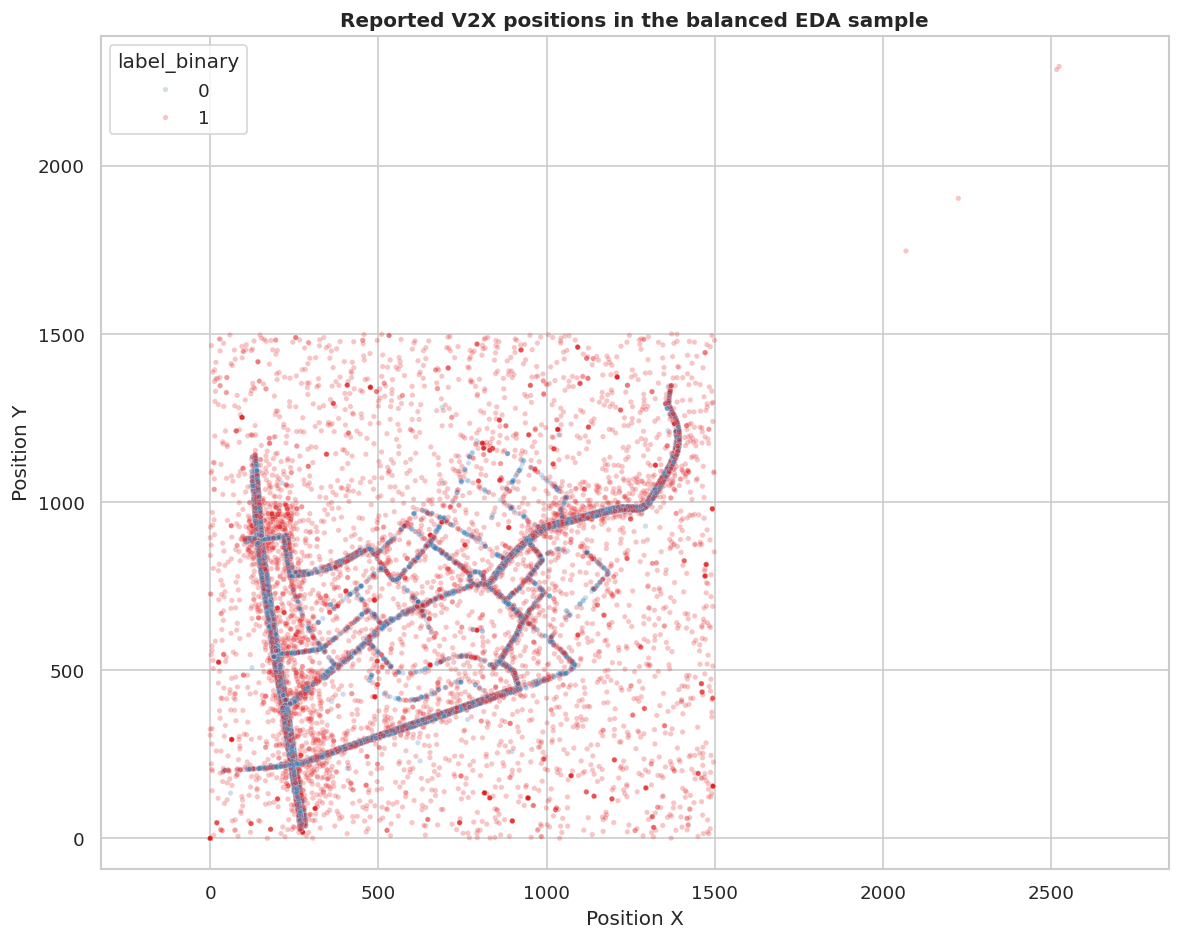

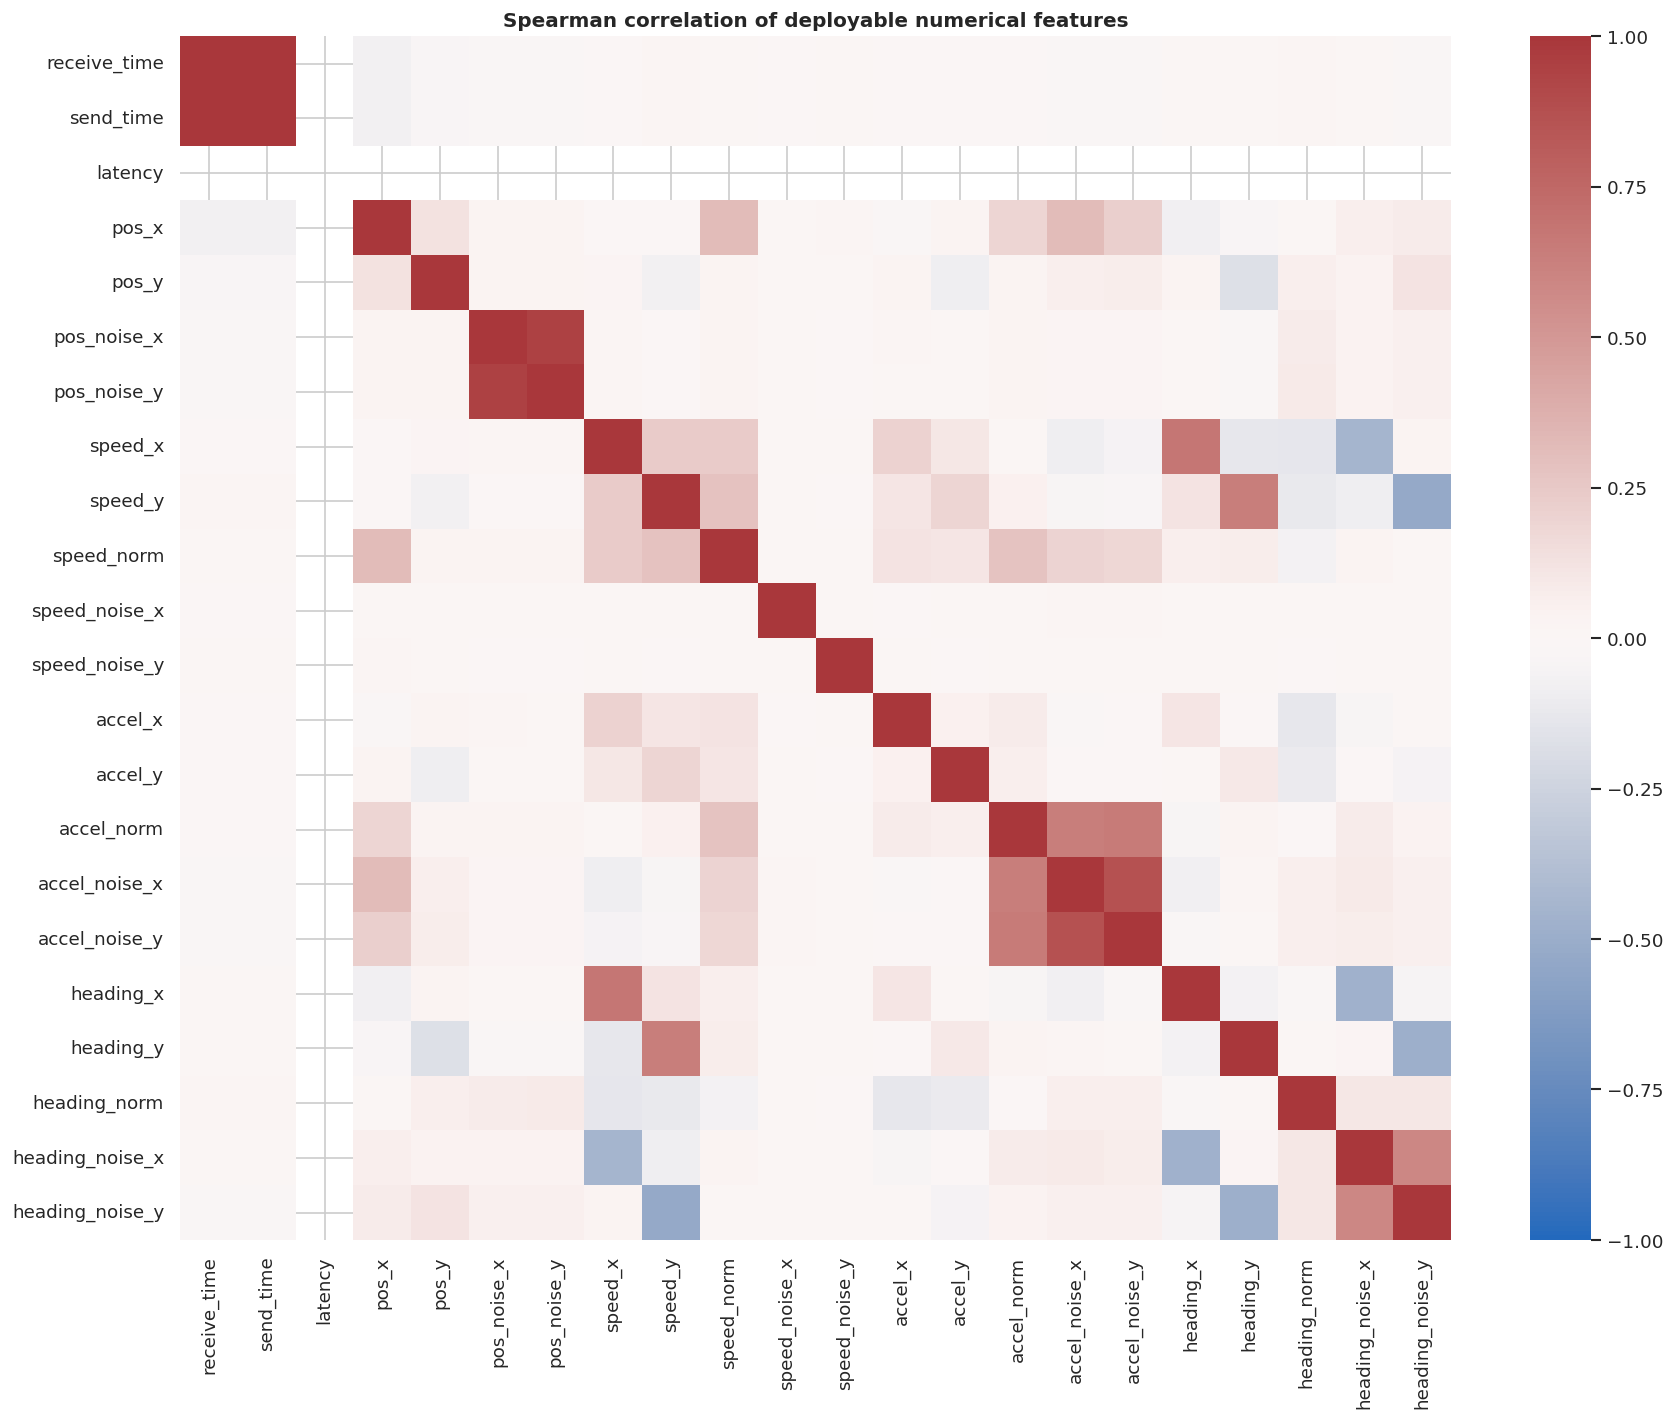

,model_feature
0,latency
1,pos_x
2,pos_y
3,pos_noise_x
4,pos_noise_y
5,speed_x
6,speed_y
7,speed_norm
8,speed_noise_x
9,speed_noise_y


Forbidden audit-only columns: ['audit_truth_available', 'audit_position_error', 'audit_speed_error', 'audit_accel_error', 'audit_heading_error']


,time_block,runs,rows,malicious,empty_runs
0,50400-54000,18,11419458,4791677,0
1,54000-57600,1,230376,68337,0


Use _0709 for an independent density/domain-shift test and reserve MixAll_0024 for final stress testing.
Tables:
  balanced_eda_sample.csv.gz 36628.8 KiB
  preprocessing_contract.json 1.2 KiB
  run_manifest.csv 1.7 KiB
  scenario_summary.csv 1.4 KiB
  time_block_summary.csv 0.1 KiB
Figures:
  01_archive_sizes.png
  02_class_distribution_by_scenario.png
  03_malicious_percentage.png
  04_missing_values.png
  05_feature_distributions.png
  06_ground_truth_audit.png
  07_position_scatter.png
  08_feature_correlation.png

EDA completed successfully.


In [1]:
# VeReMi Extension Kaggle EDA
# Generated as a cell-based Python script for Kaggle.

# %% [markdown]
# # VeReMi Extension: Leakage-Safe EDA and Preprocessing Audit
#
# This notebook performs reproducible exploratory data analysis on the **VeReMi Extension `_1416` archives** without manually extracting their nested ZIP files.
#
# Important rules implemented here:
#
# - `A0` identifies a benign vehicle.
# - Every nonzero code (`A1`, `A2`, `A13`, `A17`, etc.) identifies an attacking vehicle.
# - Received type-3 messages are labelled from the **sender's** attack code within the same simulation run.
# - Simulator ground truth is used only for audit diagrams. Ground-truth-derived columns are forbidden as deployable model inputs.
# - Random message-level train/test splitting is prohibited because the same mobility runs are reused across attack scenarios.

# %% [markdown]
# ## Kaggle setup
#
# 1. Create a Kaggle Dataset containing the 19 `_1416.zip` files and `README.md`.
# 2. Attach that dataset to this notebook with **Add Input**.
# 3. Run all cells. The notebook auto-detects the directory containing the ZIP files.
# 4. Download the generated results from `/kaggle/working/veremi_eda_outputs`.
#
# For a quick run, keep `MAX_INNER_PER_ARCHIVE = 1`. For the full two-hour audit, set it to `0`.

# %%
from pathlib import Path
import collections
import csv
import hashlib
import io
import json
import math
import random
import re
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'axes.titleweight': 'bold'})

SEED = 20261021
MAX_INNER_PER_ARCHIVE = 1   # 1 = fast EDA; 0 = all nested runs
SAMPLE_PER_CLASS_PER_SCENARIO = 5000
OUTPUT_DIR = Path('/kaggle/working/veremi_eda_outputs')
FIGURE_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print('Output:', OUTPUT_DIR)

# %%
# Locate either original outer ZIPs or Kaggle-extracted scenario folders.
candidate_dirs = []
search_dirs = [Path('/kaggle/input')] + [p for p in Path('/kaggle/input').rglob('*') if p.is_dir()]
for directory in search_dirs:
    zip_items = [p for p in directory.glob('*_1416.zip') if p.is_file()]
    folder_items = [p for p in directory.glob('*_1416') if p.is_dir()]
    if len(zip_items) + len(folder_items) >= 10:
        candidate_dirs.append((directory, zip_items + folder_items))

if not candidate_dirs:
    raise FileNotFoundError(
        'No *_1416.zip files or Kaggle-extracted *_1416 folders were found under /kaggle/input.'
    )

DATASET_DIR, sources = sorted(candidate_dirs, key=lambda item: len(item[1]), reverse=True)[0]
sources = sorted(sources, key=lambda p: p.name)
print('Dataset directory:', DATASET_DIR)
print('Scenario sources found:', len(sources))
assert len(sources) == 19, f'Expected 19 scenarios, found {len(sources)}'

def source_size(path):
    if path.is_file():
        return path.stat().st_size
    return sum(p.stat().st_size for p in path.rglob('*') if p.is_file())

inventory = pd.DataFrame({
    'archive': [p.name for p in sources],
    'layout': ['outer_zip' if p.is_file() else 'extracted_folder' for p in sources],
    'size_mb': [source_size(p) / 1024**2 for p in sources],
})
display(inventory)

# %%
# Dataset archive-size diagram
plt.figure(figsize=(11, 7))
ordered = inventory.sort_values('size_mb', ascending=True)
sns.barplot(data=ordered, y='archive', x='size_mb', color='#386cb0')
plt.title('Compressed size of VeReMi Extension scenarios')
plt.xlabel('Archive size (MiB)')
plt.ylabel('')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_archive_sizes.png', bbox_inches='tight')
plt.show()

# %%
TRACE_RE = re.compile(r'traceJSON-(\d+)-(\d+)-A(\d+)-')
SCENARIO_RE = re.compile(r'^(?P<attack>.+)_(?P<period>\d{4})(?:\.zip)?$')

class DirectoryEntry:
    def __init__(self, root, path):
        self._path = path
        self.filename = path.relative_to(root).as_posix()
        self.file_size = path.stat().st_size

class DirectoryArchive:
    """ZipFile-compatible reader for recursively extracted Kaggle folders."""
    def __init__(self, root):
        self.root = Path(root)
        self._entries = [DirectoryEntry(self.root, p) for p in self.root.rglob('*') if p.is_file()]
    def infolist(self):
        return self._entries
    def open(self, entry):
        return entry._path.open('rb')

def vector2(value):
    if not isinstance(value, list) or len(value) < 2:
        return np.nan, np.nan
    try:
        return float(value[0]), float(value[1])
    except (TypeError, ValueError):
        return np.nan, np.nan

def norm2(x, y):
    return math.hypot(x, y) if np.isfinite(x) and np.isfinite(y) else np.nan

def distance(a, b):
    ax, ay = vector2(a); bx, by = vector2(b)
    return math.hypot(ax-bx, ay-by) if all(np.isfinite([ax, ay, bx, by])) else np.nan

def iter_json_lines(stream):
    with io.TextIOWrapper(stream, encoding='utf-8', errors='replace') as reader:
        for line_number, line in enumerate(reader, 1):
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError as exc:
                raise ValueError(f'Invalid JSON line {line_number}') from exc
            if isinstance(obj, dict):
                yield obj

class Reservoir:
    def __init__(self, capacity, seed):
        self.capacity = capacity
        self.rng = random.Random(seed)
        self.seen = 0
        self.rows = []
    def add(self, row):
        self.seen += 1
        if len(self.rows) < self.capacity:
            self.rows.append(row)
        else:
            index = self.rng.randrange(self.seen)
            if index < self.capacity:
                self.rows[index] = row

def attack_mapping(inner):
    mapping = {}
    attack_codes = {}
    for entry in inner.infolist():
        match = TRACE_RE.search(Path(entry.filename).name)
        if match:
            vehicle_id, _, attack_code = map(int, match.groups())
            mapping[vehicle_id] = int(attack_code != 0)
            attack_codes[vehicle_id] = attack_code
    return mapping, attack_codes

def load_truth(inner):
    entries = [e for e in inner.infolist() if 'traceGroundTruthJSON-' in e.filename and e.filename.endswith('.json')]
    if not entries:
        return {}
    assert len(entries) == 1, f'Unexpected ground-truth file count: {len(entries)}'
    truth = {}
    with inner.open(entries[0]) as stream:
        for obj in iter_json_lines(stream):
            if isinstance(obj.get('messageID'), int):
                truth[obj['messageID']] = obj
    return truth

print('Parser ready.')

# %%
def make_row(obj, receiver_id, attacker_map, attack_codes, truth, scenario, period, run_id):
    if obj.get('type') != 3 or not isinstance(obj.get('sender'), int) or not isinstance(obj.get('messageID'), int):
        return None
    sender, message_id = obj['sender'], obj['messageID']
    px, py = vector2(obj.get('pos')); pnx, pny = vector2(obj.get('pos_noise'))
    sx, sy = vector2(obj.get('spd')); snx, sny = vector2(obj.get('spd_noise'))
    ax, ay = vector2(obj.get('acl')); anx, any_ = vector2(obj.get('acl_noise'))
    hx, hy = vector2(obj.get('hed')); hnx, hny = vector2(obj.get('hed_noise'))
    receive_time, send_time = obj.get('rcvTime', np.nan), obj.get('sendTime', np.nan)
    try: latency = float(receive_time) - float(send_time)
    except (TypeError, ValueError): latency = np.nan
    is_attack = int(attacker_map.get(sender, 0) == 1)
    gt = truth.get(message_id)
    return {
        'scenario': scenario, 'period': period, 'run_id': run_id,
        'receiver_id': receiver_id, 'sender_id': sender,
        'sender_pseudo': obj.get('senderPseudo'), 'message_id': message_id,
        'receive_time': receive_time, 'send_time': send_time, 'latency': latency,
        'pos_x': px, 'pos_y': py, 'pos_noise_x': pnx, 'pos_noise_y': pny,
        'speed_x': sx, 'speed_y': sy, 'speed_norm': norm2(sx, sy),
        'speed_noise_x': snx, 'speed_noise_y': sny,
        'accel_x': ax, 'accel_y': ay, 'accel_norm': norm2(ax, ay),
        'accel_noise_x': anx, 'accel_noise_y': any_,
        'heading_x': hx, 'heading_y': hy, 'heading_norm': norm2(hx, hy),
        'heading_noise_x': hnx, 'heading_noise_y': hny,
        'attack_code': attack_codes.get(sender, 0),
        'label_binary': is_attack,
        'label_attack': scenario if is_attack else 'Benign',
        # Audit-only: simulator truth is unavailable in deployment.
        'audit_truth_available': int(gt is not None),
        'audit_position_error': distance(obj.get('pos'), gt.get('pos')) if gt else np.nan,
        'audit_speed_error': distance(obj.get('spd'), gt.get('spd')) if gt else np.nan,
        'audit_accel_error': distance(obj.get('acl'), gt.get('acl')) if gt else np.nan,
        'audit_heading_error': distance(obj.get('hed'), gt.get('hed')) if gt else np.nan,
    }

def audit_archive(path, max_inner=1, sample_per_class=5000):
    match = SCENARIO_RE.match(path.name)
    scenario, period = match.group('attack'), match.group('period')
    reservoirs = {0: Reservoir(sample_per_class, SEED+1), 1: Reservoir(sample_per_class, SEED+2)}
    summary = collections.Counter()
    senders, receivers = set(), set()
    run_rows = []
    def process_inner(inner, run_id):
        attacker_map, attack_codes = attack_mapping(inner)
        truth = load_truth(inner)
        traces = [e for e in inner.infolist() if 'traceJSON-' in e.filename and
                  'traceGroundTruthJSON-' not in e.filename and e.filename.endswith('.json')]
        local = collections.Counter()
        for entry in traces:
            fm = TRACE_RE.search(Path(entry.filename).name)
            if not fm: continue
            receiver_id = int(fm.group(1))
            with inner.open(entry) as stream:
                for obj in iter_json_lines(stream):
                    row = make_row(obj, receiver_id, attacker_map, attack_codes, truth,
                                   scenario, period, run_id)
                    if row is None: continue
                    label = row['label_binary']
                    reservoirs[label].add(row)
                    summary['rows'] += 1; local['rows'] += 1
                    summary['malicious' if label else 'benign'] += 1
                    local['malicious' if label else 'benign'] += 1
                    summary['truth_missing'] += int(not row['audit_truth_available'])
                    senders.add(row['sender_id']); receivers.add(row['receiver_id'])
        run_rows.append({'scenario': scenario, 'run_id': run_id,
                         'rows': local['rows'], 'benign': local['benign'],
                         'malicious': local['malicious'],
                         'attacker_vehicles': sum(attacker_map.values()),
                         'vehicles': len(attacker_map), 'ground_truth_messages': len(truth)})

    if path.is_file():
        with zipfile.ZipFile(path) as outer:
            inner_entries = sorted([e for e in outer.infolist() if e.filename.lower().endswith('.zip')],
                                   key=lambda e: e.file_size, reverse=True)
            if max_inner: inner_entries = inner_entries[:max_inner]
            for nested in inner_entries:
                raw = outer.read(nested)
                with zipfile.ZipFile(io.BytesIO(raw)) as inner:
                    process_inner(inner, Path(nested.filename).stem)
    else:
        nested_zips = sorted(path.rglob('*.zip'), key=lambda p: p.stat().st_size, reverse=True)
        if nested_zips:
            if max_inner: nested_zips = nested_zips[:max_inner]
            for nested in nested_zips:
                with zipfile.ZipFile(nested) as inner:
                    process_inner(inner, nested.stem)
        else:
            # Also support both ZIP levels having been extracted.
            run_dirs = sorted({p.parent for p in path.rglob('traceJSON-*.json')})
            if max_inner: run_dirs = run_dirs[:max_inner]
            for run_dir in run_dirs:
                process_inner(DirectoryArchive(run_dir), run_dir.name)
    result = {'scenario': scenario, 'period': period, 'rows': summary['rows'],
              'benign': summary['benign'], 'malicious': summary['malicious'],
              'malicious_percent': 100*summary['malicious']/summary['rows'] if summary['rows'] else np.nan,
              'unique_senders': len(senders), 'unique_receivers': len(receivers),
              'truth_missing': summary['truth_missing']}
    return result, reservoirs[0].rows + reservoirs[1].rows, run_rows

# %%
# Stream the nested archives and create a balanced EDA sample.
scenario_summaries, sample_rows, run_manifest = [], [], []
for number, source in enumerate(sources, 1):
    print(f'[{number:02d}/{len(sources)}] {source.name}', flush=True)
    summary, sample, runs = audit_archive(source, MAX_INNER_PER_ARCHIVE,
                                          SAMPLE_PER_CLASS_PER_SCENARIO)
    scenario_summaries.append(summary)
    sample_rows.extend(sample)
    run_manifest.extend(runs)

summary_df = pd.DataFrame(scenario_summaries).sort_values('scenario').reset_index(drop=True)
sample_df = pd.DataFrame(sample_rows)
run_df = pd.DataFrame(run_manifest)

summary_df.to_csv(OUTPUT_DIR / 'scenario_summary.csv', index=False)
run_df.to_csv(OUTPUT_DIR / 'run_manifest.csv', index=False)
sample_df.to_csv(OUTPUT_DIR / 'balanced_eda_sample.csv.gz', index=False, compression='gzip')
print(f'Processed {summary_df.rows.sum():,} received messages; saved {len(sample_df):,} sampled rows.')
display(summary_df)

# %%
# Diagram 2: binary class distribution by scenario
plot_df = summary_df.melt(id_vars='scenario', value_vars=['benign', 'malicious'],
                          var_name='class', value_name='messages')
plt.figure(figsize=(13, 8))
sns.barplot(data=plot_df, y='scenario', x='messages', hue='class',
            palette={'benign':'#4daf4a', 'malicious':'#e41a1c'})
plt.title('Benign and malicious received messages by scenario')
plt.xlabel('Received-message observations'); plt.ylabel('')
plt.legend(title='Class')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'02_class_distribution_by_scenario.png', bbox_inches='tight'); plt.show()

# Diagram 3: malicious percentage
plt.figure(figsize=(12, 7))
sns.barplot(data=summary_df.sort_values('malicious_percent'), y='scenario', x='malicious_percent', color='#e6550d')
plt.axvline(summary_df.malicious.sum()/summary_df.rows.sum()*100, color='black', ls='--', label='Overall rate')
plt.title('Malicious-observation percentage by scenario'); plt.xlabel('Malicious observations (%)'); plt.ylabel('')
plt.legend(); plt.tight_layout(); plt.savefig(FIGURE_DIR/'03_malicious_percentage.png', bbox_inches='tight'); plt.show()

# %%
# Diagram 4: missing-value profile in the balanced sample
missing = (sample_df.isna().mean()*100).sort_values(ascending=False)
missing = missing[missing > 0].reset_index()
missing.columns = ['feature', 'missing_percent']
display(missing)
if not missing.empty:
    plt.figure(figsize=(10, max(4, len(missing)*0.3)))
    sns.barplot(data=missing, y='feature', x='missing_percent', color='#756bb1')
    plt.title('Missing values in balanced EDA sample'); plt.xlabel('Missing (%)'); plt.ylabel('')
    plt.tight_layout(); plt.savefig(FIGURE_DIR/'04_missing_values.png', bbox_inches='tight'); plt.show()

# %%
# Diagram 5: deployable numerical feature distributions
features = ['speed_norm', 'accel_norm', 'latency', 'pos_noise_x', 'speed_noise_x']
fig, axes = plt.subplots(len(features), 1, figsize=(11, 3.2*len(features)))
for ax, feature in zip(axes, features):
    clean = sample_df[[feature, 'label_binary']].replace([np.inf, -np.inf], np.nan).dropna()
    # Clip only for visualization; raw values remain unchanged.
    lo, hi = clean[feature].quantile([0.01, 0.99])
    clean = clean[clean[feature].between(lo, hi)]
    sns.histplot(data=clean, x=feature, hue='label_binary', stat='density', common_norm=False,
                 element='step', bins=60, ax=ax, palette={0:'#4daf4a',1:'#e41a1c'})
    ax.set_title(f'{feature}: benign versus malicious (1st–99th percentile shown)')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'05_feature_distributions.png', bbox_inches='tight'); plt.show()

# %%
# Diagram 6: simulator-truth discrepancy—EDA only, never a model input
audit_features = ['audit_position_error','audit_speed_error','audit_accel_error','audit_heading_error']
audit_long = sample_df.melt(id_vars=['label_binary'], value_vars=audit_features,
                            var_name='audit_metric', value_name='error').dropna()
audit_long['log1p_error'] = np.log1p(audit_long['error'].clip(lower=0))
plt.figure(figsize=(12, 6))
sns.boxplot(data=audit_long, x='audit_metric', y='log1p_error', hue='label_binary',
            showfliers=False, palette={0:'#4daf4a',1:'#e41a1c'})
plt.xticks(rotation=20, ha='right'); plt.ylabel('log(1 + simulator-truth error)')
plt.title('Attack effect confirmed using simulator truth (audit only)')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'06_ground_truth_audit.png', bbox_inches='tight'); plt.show()

# %%
# Diagram 7: spatial pattern sample
spatial = sample_df[['pos_x','pos_y','label_binary','scenario']].dropna().sample(
    min(30000, len(sample_df)), random_state=SEED)
plt.figure(figsize=(10, 8))
sns.scatterplot(data=spatial, x='pos_x', y='pos_y', hue='label_binary',
                palette={0:'#377eb8',1:'#e41a1c'}, alpha=.25, s=10)
plt.title('Reported V2X positions in the balanced EDA sample')
plt.xlabel('Position X'); plt.ylabel('Position Y'); plt.axis('equal')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'07_position_scatter.png', bbox_inches='tight'); plt.show()

# %%
# Diagram 8: correlation heatmap for allowed raw/model-derived numerical variables
forbidden = [c for c in sample_df.columns if c.startswith('audit_')]
identifier_columns = ['receiver_id','sender_id','sender_pseudo','message_id','attack_code','label_binary']
numeric = sample_df.select_dtypes(include='number').drop(columns=forbidden, errors='ignore')
numeric = numeric.drop(columns=[c for c in identifier_columns if c in numeric], errors='ignore')
corr = numeric.corr(method='spearman')
plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1, square=False)
plt.title('Spearman correlation of deployable numerical features')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'08_feature_correlation.png', bbox_inches='tight'); plt.show()

# %%
# Leakage-safe preprocessing contract
AUDIT_ONLY = [c for c in sample_df if c.startswith('audit_')]
IDENTIFIERS = ['scenario','period','run_id','receiver_id','sender_id','sender_pseudo',
               'message_id','attack_code','receive_time','send_time']
TARGETS = ['label_binary','label_attack']
MODEL_FEATURES = [c for c in sample_df.columns if c not in AUDIT_ONLY + IDENTIFIERS + TARGETS]

contract = {
    'model_features': MODEL_FEATURES,
    'targets': TARGETS,
    'group_split_key': 'run_id / shared temporal block',
    'forbidden_model_inputs': AUDIT_ONLY,
    'identifier_columns': IDENTIFIERS,
    'rules': [
        'Fit imputers/scalers/feature selection on training runs only.',
        'Create temporal windows only after assigning whole runs to partitions.',
        'Do not use SMOTE on time-series windows before splitting.',
        'Do not randomly split messages; mobility traces recur across scenarios.',
        'Use macro-F1, per-class recall, MCC and AUPRC in addition to accuracy.'
    ]
}
(OUTPUT_DIR/'preprocessing_contract.json').write_text(json.dumps(contract, indent=2))
display(pd.DataFrame({'model_feature': MODEL_FEATURES}))
print('Forbidden audit-only columns:', AUDIT_ONLY)

# %%
# Time-block audit: determine whether a defensible 3-way split is possible.
run_df['time_block'] = run_df['run_id'].str.extract(r'VeReMi_(\d+_\d+)_', expand=False).str.replace('_','-')
block_summary = run_df.groupby('time_block', dropna=False).agg(
    runs=('run_id','size'), rows=('rows','sum'), malicious=('malicious','sum'),
    empty_runs=('rows', lambda x: int((x==0).sum()))).reset_index()
display(block_summary)
block_summary.to_csv(OUTPUT_DIR/'time_block_summary.csv', index=False)

usable_blocks = block_summary.loc[block_summary.rows > 0, 'time_block'].nunique()
if usable_blocks < 3:
    print('WARNING: fewer than three non-empty shared time blocks are available.')
    print('Use _0709 for an independent density/domain-shift test and reserve MixAll_0024 for final stress testing.')

# %%
# Final output inventory
print('Tables:')
for path in sorted(OUTPUT_DIR.glob('*')):
    if path.is_file(): print(' ', path.name, f'{path.stat().st_size/1024:.1f} KiB')
print('Figures:')
for path in sorted(FIGURE_DIR.glob('*.png')):
    print(' ', path.name)
print('\nEDA completed successfully.')


In [2]:
from pathlib import Path
import shutil

# Folder containing the completed EDA outputs
OUTPUT_DIR = Path("/kaggle/working/veremi_eda_outputs")

# ZIP file path (do not include .zip here)
ZIP_BASE = Path("/kaggle/working/veremi_eda_outputs")

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(f"Output folder not found: {OUTPUT_DIR}")

zip_path = shutil.make_archive(
    base_name=str(ZIP_BASE),
    format="zip",
    root_dir=str(OUTPUT_DIR)
)

zip_size_mb = Path(zip_path).stat().st_size / (1024**2)

print("EDA outputs compressed successfully.")
print(f"ZIP file: {zip_path}")
print(f"ZIP size: {zip_size_mb:.2f} MB")

EDA outputs compressed successfully.
ZIP file: /kaggle/working/veremi_eda_outputs.zip
ZIP size: 38.33 MB


In [3]:
#!/usr/bin/env python3
"""Leakage-safe preprocessing for the VeReMi Extension EDA export.

Designed for Kaggle. It accepts either balanced_eda_sample.csv.gz directly or
the veremi_eda_outputs.zip produced by the EDA script. RAPIDS/cuDF is used for
loading and basic cleaning when available; ordered/grouped feature engineering
and sequence construction use pandas/NumPy for reproducibility.
"""

from __future__ import annotations

import argparse
import gzip
import hashlib
import json
import math
import shutil
import sys
import tempfile
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd


SEED = 42
FORBIDDEN = [
    "audit_truth_available",
    "audit_position_error",
    "audit_speed_error",
    "audit_accel_error",
    "audit_heading_error",
]
ID_COLUMNS = [
    "scenario", "period", "run_id", "receiver_id", "sender_id",
    "sender_pseudo", "message_id", "receive_time", "send_time",
]
BASE_FEATURES = [
    "latency", "pos_x", "pos_y", "pos_noise_x", "pos_noise_y",
    "speed_x", "speed_y", "speed_norm", "speed_noise_x", "speed_noise_y",
    "accel_x", "accel_y", "accel_norm", "accel_noise_x", "accel_noise_y",
    "heading_x", "heading_y", "heading_norm", "heading_noise_x",
    "heading_noise_y",
]
FAULT_CLASSES = {
    "ConstPosOffset", "ConstSpeedOffset", "RandomPosOffset", "RandomSpeedOffset"
}
DEFAULT_UNKNOWN = ["DataReplaySybil", "DoSDisruptiveSybil", "GridSybil"]


def parse_args() -> argparse.Namespace:
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--input", type=Path, default=None,
                   help="CSV.GZ or EDA ZIP. Auto-detected under /kaggle/input if omitted.")
    p.add_argument("--output", type=Path,
                   default=Path("/kaggle/working/veremi_preprocessed"))
    p.add_argument("--engine", choices=["auto", "pandas", "cudf"], default="auto")
    p.add_argument("--unknown-attacks", default=",".join(DEFAULT_UNKNOWN),
                   help="Comma-separated attack classes held out from training.")
    p.add_argument("--sequence-length", type=int, default=32)
    p.add_argument("--sequence-stride", type=int, default=8)
    p.add_argument("--max-sequences-per-shard", type=int, default=25000)
    p.add_argument("--skip-sequences", action="store_true")
    p.add_argument("--zip-output", action="store_true")
    # Jupyter/Colab/Kaggle kernels inject arguments such as
    # ``-f /path/to/kernel.json``. Ignore only unknown kernel arguments so the
    # same source works as a script and when pasted into a notebook cell.
    args, unknown = p.parse_known_args()
    if unknown:
        print(f"Ignoring notebook arguments: {unknown}")
    return args


def locate_input(user_path: Path | None) -> Path:
    if user_path is not None:
        if not user_path.exists():
            raise FileNotFoundError(user_path)
        return user_path
    roots = [Path("/kaggle/input"), Path.cwd()]
    patterns = [
        "**/balanced_eda_sample.csv",
        "**/balanced_eda_sample.csv.gz",
        "**/veremi_eda_outputs.zip",
    ]
    found: list[Path] = []
    for root in roots:
        if root.exists():
            for pattern in patterns:
                found.extend(root.glob(pattern))
    if not found:
        raise FileNotFoundError(
            "Could not find balanced_eda_sample.csv, balanced_eda_sample.csv.gz, "
            "or veremi_eda_outputs.zip. "
            "Pass --input explicitly."
        )
    return sorted(found, key=lambda x: ("balanced_eda_sample" not in x.name, len(str(x))))[0]


def extract_csv_from_zip(path: Path, temp_dir: Path) -> Path:
    with zipfile.ZipFile(path) as zf:
        member = next((n for n in zf.namelist() if n.endswith("balanced_eda_sample.csv.gz")), None)
        if member is None:
            raise FileNotFoundError("balanced_eda_sample.csv.gz is absent from the EDA ZIP")
        target = temp_dir / "balanced_eda_sample.csv.gz"
        with zf.open(member) as src, target.open("wb") as dst:
            shutil.copyfileobj(src, dst)
    return target


def load_data(path: Path, engine: str) -> tuple[pd.DataFrame, str]:
    selected = "pandas"
    if engine in {"auto", "cudf"}:
        try:
            import cudf  # type: ignore
            gdf = cudf.read_csv(str(path))
            existing_forbidden = [c for c in FORBIDDEN if c in gdf.columns]
            gdf = gdf.drop(columns=existing_forbidden)
            gdf = gdf.drop_duplicates()
            df = gdf.to_pandas()
            selected = "cudf+GPU (load/clean) -> pandas (ordered features)"
            return df, selected
        except Exception as exc:
            if engine == "cudf":
                raise RuntimeError(f"cuDF was requested but failed: {exc}") from exc
            print(f"cuDF unavailable; using pandas: {exc}")
    df = pd.read_csv(path, compression="infer", low_memory=False)
    df = df.drop(columns=[c for c in FORBIDDEN if c in df.columns], errors="ignore")
    df = df.drop_duplicates().reset_index(drop=True)
    return df, selected


def validate(df: pd.DataFrame) -> None:
    required = set(ID_COLUMNS + BASE_FEATURES + ["label_binary", "label_attack"])
    missing = sorted(required.difference(df.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    leaked = sorted(set(FORBIDDEN).intersection(df.columns))
    if leaked:
        raise ValueError(f"Leakage columns remain: {leaked}")


def clean_and_label(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    numeric = [c for c in ID_COLUMNS + BASE_FEATURES if c in df.columns and c not in {"scenario", "run_id"}]
    for c in numeric:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[BASE_FEATURES] = df[BASE_FEATURES].replace([np.inf, -np.inf], np.nan)
    # Missing input values are retained temporarily and imputed using training-only medians later.
    df["label_binary"] = pd.to_numeric(df["label_binary"], errors="coerce").fillna(0).astype("int8")
    df["label_attack"] = df["label_attack"].fillna("Unknown").astype(str)
    df["target_3class"] = np.where(
        df["label_binary"].eq(0), "Benign",
        np.where(df["label_attack"].isin(FAULT_CLASSES), "Fault", "Attack")
    )
    # Stable 20-class encoding: Benign=0, other class names alphabetically.
    attack_classes = ["Benign"] + sorted(x for x in df["label_attack"].unique() if x != "Benign")
    attack_map = {name: idx for idx, name in enumerate(attack_classes)}
    three_map = {"Benign": 0, "Fault": 1, "Attack": 2}
    df["target_multiclass"] = df["label_attack"].map(attack_map).astype("int16")
    df["target_3class_id"] = df["target_3class"].map(three_map).astype("int8")
    # Immutable observation key used by every baseline, SOTA model and ablation.
    # Include receiver because a broadcast can be observed by several receivers.
    uid_cols = [
        "scenario", "run_id", "receiver_id", "sender_id", "sender_pseudo",
        "message_id", "receive_time", "send_time", "label_attack",
    ]
    hashes = pd.util.hash_pandas_object(df[uid_cols].astype(str), index=False).astype("uint64")
    df["row_uid"] = hashes.map(lambda x: f"{int(x):016x}")
    if df["row_uid"].duplicated().any():
        raise ValueError("Duplicate immutable row_uid values detected after deduplication")
    return df


def add_physics_and_multiscale_features(df: pd.DataFrame) -> tuple[pd.DataFrame, list[str]]:
    df = df.sort_values(
        ["scenario", "run_id", "receiver_id", "sender_id", "receive_time"],
        kind="mergesort"
    ).reset_index(drop=True)
    eps = 1e-6
    df["pos_noise_norm"] = np.hypot(df["pos_noise_x"], df["pos_noise_y"])
    df["speed_noise_norm"] = np.hypot(df["speed_noise_x"], df["speed_noise_y"])
    df["accel_noise_norm"] = np.hypot(df["accel_noise_x"], df["accel_noise_y"])
    df["heading_noise_norm"] = np.hypot(df["heading_noise_x"], df["heading_noise_y"])
    df["heading_angle"] = np.arctan2(df["heading_y"], df["heading_x"])
    df["speed_heading_alignment"] = (
        df["speed_x"] * df["heading_x"] + df["speed_y"] * df["heading_y"]
    ) / (df["speed_norm"].abs() * df["heading_norm"].abs() + eps)
    df["longitudinal_accel"] = (
        df["accel_x"] * df["heading_x"] + df["accel_y"] * df["heading_y"]
    ) / (df["heading_norm"].abs() + eps)
    df["kinetic_proxy"] = 0.5 * np.square(df["speed_norm"].clip(-1000, 1000))

    group_cols = ["scenario", "run_id", "receiver_id", "sender_id"]
    grp = df.groupby(group_cols, sort=False, observed=True)
    dt = grp["receive_time"].diff()
    dx = grp["pos_x"].diff()
    dy = grp["pos_y"].diff()
    dvx = grp["speed_x"].diff()
    dvy = grp["speed_y"].diff()
    df["delta_t"] = dt
    df["observed_speed"] = np.hypot(dx, dy) / dt.where(dt > eps)
    df["speed_consistency_error"] = (df["observed_speed"] - df["speed_norm"]).abs()
    df["observed_accel"] = np.hypot(dvx, dvy) / dt.where(dt > eps)
    df["accel_consistency_error"] = (df["observed_accel"] - df["accel_norm"]).abs()
    df["jerk_norm"] = grp["accel_norm"].diff().abs() / dt.where(dt > eps)
    df["heading_change"] = grp["heading_angle"].diff().abs()

    engineered = [
        "pos_noise_norm", "speed_noise_norm", "accel_noise_norm", "heading_noise_norm",
        "heading_angle", "speed_heading_alignment", "longitudinal_accel", "kinetic_proxy",
        "delta_t", "observed_speed", "speed_consistency_error", "observed_accel",
        "accel_consistency_error", "jerk_norm", "heading_change",
    ]

    # Past-only multiscale statistics. shift(1) prevents the current target-bearing row
    # from influencing its own contextual features.
    scale_specs = {"short": 5, "medium": 20, "long": 50}
    for source in ["latency", "speed_norm", "accel_norm", "speed_consistency_error"]:
        shifted = grp[source].shift(1)
        shifted_df = df[group_cols].copy()
        shifted_df["value"] = shifted
        sg = shifted_df.groupby(group_cols, sort=False, observed=True)["value"]
        for scale, window in scale_specs.items():
            mean_col = f"{source}_{scale}_mean"
            std_col = f"{source}_{scale}_std"
            df[mean_col] = sg.rolling(window, min_periods=1).mean().reset_index(level=group_cols, drop=True)
            df[std_col] = sg.rolling(window, min_periods=2).std().reset_index(level=group_cols, drop=True)
            engineered.extend([mean_col, std_col])
    return df, engineered


def stable_bucket(value: object, seed: int = SEED) -> int:
    raw = f"{seed}|{value}".encode("utf-8")
    return int(hashlib.blake2b(raw, digest_size=8).hexdigest(), 16) % 100


def assign_splits(df: pd.DataFrame, unknown: set[str]) -> pd.DataFrame:
    df = df.copy()
    # Sender-disjoint split: the same physical sender cannot occur across train/val/test.
    buckets = df["sender_id"].map(stable_bucket)
    df["split"] = np.where(buckets < 70, "train", np.where(buckets < 85, "validation", "test"))
    is_unknown = df["label_attack"].isin(unknown)
    # Unknown attacks are evaluated only on test-bucket senders. Unknown rows
    # belonging to train/validation senders are excluded entirely, preventing
    # entity overlap between open-set evaluation and model development.
    df.loc[is_unknown & (buckets < 70), "split"] = "excluded_unknown_train_sender"
    df.loc[is_unknown & buckets.between(70, 84), "split"] = "excluded_unknown_validation_sender"
    df.loc[is_unknown & (buckets >= 85), "split"] = "open_set_attack"
    return df


def audit_split_integrity(df: pd.DataFrame, unknown: set[str]) -> dict:
    closed = ["train", "validation", "test"]
    row_sets = {s: set(df.loc[df["split"].eq(s), "row_uid"]) for s in closed}
    sender_sets = {s: set(df.loc[df["split"].eq(s), "sender_id"]) for s in closed}
    row_overlap = {}
    sender_overlap = {}
    for i, left in enumerate(closed):
        for right in closed[i + 1:]:
            row_overlap[f"{left}__{right}"] = len(row_sets[left] & row_sets[right])
            sender_overlap[f"{left}__{right}"] = len(sender_sets[left] & sender_sets[right])
    unknown_in_closed = int(
        df.loc[df["split"].isin(closed), "label_attack"].isin(unknown).sum()
    )
    open_senders = set(df.loc[df["split"].eq("open_set_attack"), "sender_id"])
    open_sender_overlap = {
        "open__train": len(open_senders & sender_sets["train"]),
        "open__validation": len(open_senders & sender_sets["validation"]),
    }
    if (any(row_overlap.values()) or any(sender_overlap.values()) or
            any(open_sender_overlap.values()) or unknown_in_closed):
        raise RuntimeError(
            f"Split integrity failure: row_overlap={row_overlap}, "
            f"sender_overlap={sender_overlap}, open_sender_overlap={open_sender_overlap}, "
            f"unknown_in_closed={unknown_in_closed}"
        )
    manifest_text = "\n".join(
        f"{uid},{split}" for uid, split in
        df[["row_uid", "split"]].sort_values("row_uid").itertuples(index=False, name=None)
    )
    return {
        "row_overlap": row_overlap,
        "sender_overlap": sender_overlap,
        "open_set_sender_overlap_with_train_or_validation": open_sender_overlap,
        "unknown_attack_rows_in_closed_splits": unknown_in_closed,
        "manifest_sha256": hashlib.sha256(manifest_text.encode("utf-8")).hexdigest(),
        "status": "PASS",
    }


def fit_imputer_scaler(df: pd.DataFrame, features: list[str]) -> dict:
    train = df.loc[df["split"].eq("train"), features]
    med = train.median(numeric_only=True).reindex(features).fillna(0.0)
    filled = train.fillna(med)
    mean = filled.mean().reindex(features).fillna(0.0)
    std = filled.std(ddof=0).reindex(features).replace(0, 1).fillna(1.0)
    return {
        "features": features,
        "median": med.to_dict(),
        "mean": mean.to_dict(),
        "std": std.to_dict(),
    }


def apply_scaler(df: pd.DataFrame, scaler: dict) -> pd.DataFrame:
    features = scaler["features"]
    med = pd.Series(scaler["median"])
    mean = pd.Series(scaler["mean"])
    std = pd.Series(scaler["std"])
    values = df[features].replace([np.inf, -np.inf], np.nan).fillna(med)
    values = ((values - mean) / std).clip(-10, 10).astype("float32")
    out = df.copy()
    out[features] = values
    return out


def save_frame(df: pd.DataFrame, path_without_suffix: Path) -> str:
    try:
        path = path_without_suffix.with_suffix(".parquet")
        df.to_parquet(path, index=False, compression="snappy")
    except Exception as exc:
        path = path_without_suffix.with_suffix(".csv.gz")
        print(f"Parquet unavailable ({exc}); writing {path.name}")
        df.to_csv(path, index=False, compression="gzip")
    return path.name


def make_sequences(
    frame: pd.DataFrame,
    features: list[str],
    output_dir: Path,
    split_name: str,
    length: int,
    stride: int,
    max_per_shard: int,
) -> dict:
    output_dir.mkdir(parents=True, exist_ok=True)
    groups = ["scenario", "run_id", "receiver_id", "sender_id"]
    xs: list[np.ndarray] = []
    yb: list[int] = []
    y3: list[int] = []
    ym: list[int] = []
    shard = 0
    total = 0
    files: list[str] = []

    def flush() -> None:
        nonlocal shard, total, xs, yb, y3, ym
        if not xs:
            return
        file = output_dir / f"{split_name}_seq_{shard:03d}.npz"
        np.savez_compressed(
            file,
            X=np.stack(xs).astype("float32"),
            y_binary=np.asarray(yb, dtype="int8"),
            y_3class=np.asarray(y3, dtype="int8"),
            y_multiclass=np.asarray(ym, dtype="int16"),
        )
        files.append(file.name)
        total += len(xs)
        shard += 1
        xs, yb, y3, ym = [], [], [], []

    ordered = frame.sort_values(groups + ["receive_time"], kind="mergesort")
    for _, part in ordered.groupby(groups, sort=False, observed=True):
        if len(part) < length:
            continue
        x = part[features].to_numpy(dtype="float32", copy=False)
        b = part["label_binary"].to_numpy()
        c3 = part["target_3class_id"].to_numpy()
        mc = part["target_multiclass"].to_numpy()
        for start in range(0, len(part) - length + 1, stride):
            end = start + length
            xs.append(x[start:end])
            yb.append(int(b[end - 1]))
            y3.append(int(c3[end - 1]))
            ym.append(int(mc[end - 1]))
            if len(xs) >= max_per_shard:
                flush()
    flush()
    return {"split": split_name, "sequences": total, "files": files}


def main() -> None:
    args = parse_args()
    started = time.time()
    np.random.seed(SEED)
    args.output.mkdir(parents=True, exist_ok=True)
    # Keep temporary extraction beside the requested output. This works in
    # restricted notebook environments where the system temp folder is read-only.
    temp_parent = args.output.parent
    temp_parent.mkdir(parents=True, exist_ok=True)
    temp_root = Path(tempfile.mkdtemp(prefix="veremi_preprocess_", dir=temp_parent))
    try:
        input_path = locate_input(args.input)
        csv_path = extract_csv_from_zip(input_path, temp_root) if input_path.suffix.lower() == ".zip" else input_path
        print(f"Input: {input_path}")
        df, engine_used = load_data(csv_path, args.engine)
        print(f"Engine: {engine_used}; rows after deduplication: {len(df):,}")
        validate(df)
        df = clean_and_label(df)
        df, engineered = add_physics_and_multiscale_features(df)

        unknown = {x.strip() for x in args.unknown_attacks.split(",") if x.strip()}
        missing_unknown = sorted(unknown.difference(df["label_attack"].unique()))
        if missing_unknown:
            raise ValueError(f"Unknown holdout labels absent from data: {missing_unknown}")
        df = assign_splits(df, unknown)
        split_audit = audit_split_integrity(df, unknown)

        features = BASE_FEATURES + engineered
        # These are metadata/targets only and are never added to features.
        assert not set(FORBIDDEN + ID_COLUMNS + ["label_binary", "label_attack"]).intersection(features)
        scaler = fit_imputer_scaler(df, features)
        df = apply_scaler(df, scaler)

        # Open-set test = held-out attacks plus ordinary benign test examples.
        open_df = pd.concat([
            df.loc[df["split"].eq("open_set_attack")],
            df.loc[df["split"].eq("test") & df["label_binary"].eq(0)],
        ], ignore_index=True).drop_duplicates()
        open_df["is_unknown"] = open_df["label_attack"].isin(unknown).astype("int8")

        keep = ["row_uid"] + ID_COLUMNS + features + [
            "label_binary", "label_attack", "target_3class", "target_3class_id",
            "target_multiclass", "split",
        ]
        table_dir = args.output / "tables"
        table_dir.mkdir(exist_ok=True)
        manifest_columns = [
            "row_uid", "split", "scenario", "run_id", "sender_id", "receiver_id",
            "receive_time", "label_binary", "label_attack", "target_3class_id",
            "target_multiclass",
        ]
        df[manifest_columns].sort_values("row_uid").to_csv(
            args.output / "split_manifest.csv.gz", index=False, compression="gzip"
        )
        written = {}
        for split in ["train", "validation", "test"]:
            part = df.loc[df["split"].eq(split), keep].reset_index(drop=True)
            written[split] = save_frame(part, table_dir / split)
        written["open_set_test"] = save_frame(open_df[keep + ["is_unknown"]], table_dir / "open_set_test")

        attack_classes = ["Benign"] + sorted(x for x in df["label_attack"].unique() if x != "Benign")
        metadata = {
            "input": str(input_path),
            "engine": engine_used,
            "seed": SEED,
            "rows_loaded": int(len(df)),
            "feature_count": len(features),
            "features": features,
            "forbidden_columns": FORBIDDEN,
            "excluded_metadata_columns": ID_COLUMNS,
            "attack_to_id": {name: i for i, name in enumerate(attack_classes)},
            "three_class_to_id": {"Benign": 0, "Fault": 1, "Attack": 2},
            "fault_classes": sorted(FAULT_CLASSES),
            "open_set_attacks": sorted(unknown),
            "split_strategy": "sender-disjoint stable hash: 70% train, 15% validation, 15% test",
            "split_integrity_audit": split_audit,
            "comparison_rule": (
                "All baselines, SOTA models, proposed models and ablations must use "
                "split_manifest.csv.gz unchanged; fit preprocessing only on split=train."
            ),
            "table_files": written,
            "row_counts": {k: int(v) for k, v in df["split"].value_counts().to_dict().items()},
            "open_set_rows": int(len(open_df)),
            "sequence_length": args.sequence_length,
            "sequence_stride": args.sequence_stride,
        }
        (args.output / "scaler.json").write_text(json.dumps(scaler, indent=2), encoding="utf-8")

        sequence_manifest = []
        if not args.skip_sequences:
            seq_dir = args.output / "sequences"
            for split in ["train", "validation", "test"]:
                part = df.loc[df["split"].eq(split)]
                sequence_manifest.append(make_sequences(
                    part, features, seq_dir, split, args.sequence_length,
                    args.sequence_stride, args.max_sequences_per_shard,
                ))
            sequence_manifest.append(make_sequences(
                open_df, features, seq_dir, "open_set_test", args.sequence_length,
                args.sequence_stride, args.max_sequences_per_shard,
            ))
        metadata["sequence_manifest"] = sequence_manifest
        metadata["elapsed_seconds"] = round(time.time() - started, 2)
        (args.output / "preprocessing_report.json").write_text(
            json.dumps(metadata, indent=2), encoding="utf-8"
        )
        pd.DataFrame([
            {"split": k, "rows": v} for k, v in metadata["row_counts"].items()
        ] + [{"split": "open_set_test_with_benign", "rows": len(open_df)}]).to_csv(
            args.output / "split_summary.csv", index=False
        )

        print(json.dumps({
            "output": str(args.output),
            "rows": metadata["row_counts"],
            "features": len(features),
            "open_set_attacks": sorted(unknown),
            "sequences": sequence_manifest,
            "elapsed_seconds": metadata["elapsed_seconds"],
        }, indent=2))

        if args.zip_output:
            archive = shutil.make_archive(str(args.output), "zip", root_dir=args.output)
            print(f"ZIP: {archive} ({Path(archive).stat().st_size / 2**20:.2f} MiB)")
    finally:
        shutil.rmtree(temp_root, ignore_errors=True)


if __name__ == "__main__":
    main()


Ignoring notebook arguments: ['-f', '/root/.local/share/jupyter/runtime/kernel-c00495c6-a4e4-444b-aec9-4760ba9fab8e.json']
Input: /kaggle/input/datasets/kabil08/verimi-eda/balanced_eda_sample.csv
Engine: cudf+GPU (load/clean) -> pandas (ordered features); rows after deduplication: 190,000
{
  "output": "/kaggle/working/veremi_preprocessed",
  "rows": {
    "train": 123659,
    "test": 26484,
    "validation": 24857,
    "excluded_unknown_train_sender": 10548,
    "excluded_unknown_validation_sender": 2366,
    "open_set_attack": 2086
  },
  "features": 59,
  "open_set_attacks": [
    "DataReplaySybil",
    "DoSDisruptiveSybil",
    "GridSybil"
  ],
  "sequences": [
    {
      "split": "train",
      "sequences": 0,
      "files": []
    },
    {
      "split": "validation",
      "sequences": 0,
      "files": []
    },
    {
      "split": "test",
      "sequences": 0,
      "files": []
    },
    {
      "split": "open_set_test",
      "sequences": 0,
      "files": []
    }
  ],
  

In [4]:
from pathlib import Path
import shutil

OUTPUT_DIR = Path("/kaggle/working/veremi_preprocessed")

print("Generated files:")
for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(f"{file.relative_to(OUTPUT_DIR)}: {file.stat().st_size / 1024**2:.2f} MB")

archive = shutil.make_archive(
    "/kaggle/working/veremi_preprocessed",
    "zip",
    root_dir=OUTPUT_DIR
)

print(f"\nZIP created: {archive}")
print(f"ZIP size: {Path(archive).stat().st_size / 1024**2:.2f} MB")

Generated files:
preprocessing_report.json: 0.00 MB
scaler.json: 0.01 MB
split_manifest.csv.gz: 5.09 MB
split_summary.csv: 0.00 MB
tables/open_set_test.parquet: 3.47 MB
tables/test.parquet: 5.14 MB
tables/train.parquet: 24.84 MB
tables/validation.parquet: 4.84 MB

ZIP created: /kaggle/working/veremi_preprocessed.zip
ZIP size: 39.03 MB


In [ ]:
#!/usr/bin/env python3
"""Create leakage-safe chronological VeReMi sequence shards from raw folders.

Run on Kaggle with the original Vanet-DS input attached. The script never uses
ground-truth audit fields. Splits are deterministic and sender-disjoint.
Unknown attack families are evaluated only on test-bucket senders.
"""
from __future__ import annotations

import argparse, hashlib, io, json, math, re, shutil, time
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
TRACE_RE = re.compile(r"traceJSON-(\d+)-(\d+)-A(\d+)-")
SCENARIO_RE = re.compile(r"^(?P<attack>.+)_(?P<period>\d{4})$")
FEATURES = [
    "latency", "pos_x", "pos_y", "pos_noise_x", "pos_noise_y",
    "speed_x", "speed_y", "speed_norm", "speed_noise_x", "speed_noise_y",
    "accel_x", "accel_y", "accel_norm", "accel_noise_x", "accel_noise_y",
    "heading_x", "heading_y", "heading_norm", "heading_noise_x", "heading_noise_y",
]
FAULTS = {"ConstPosOffset", "ConstSpeedOffset", "RandomPosOffset", "RandomSpeedOffset"}
DEFAULT_UNKNOWN = {"DataReplaySybil", "DoSDisruptiveSybil", "GridSybil"}


def args():
    p = argparse.ArgumentParser()
    p.add_argument("--input", type=Path, default=None)
    p.add_argument("--output", type=Path, default=Path("/kaggle/working/veremi_full_sequences"))
    p.add_argument("--length", type=int, default=32)
    p.add_argument("--stride", type=int, default=8)
    p.add_argument("--shard-size", type=int, default=10000)
    p.add_argument("--unknown", default=",".join(sorted(DEFAULT_UNKNOWN)))
    p.add_argument("--zip-output", action="store_true")
    a, extra = p.parse_known_args()
    if extra: print("Ignoring notebook arguments:", extra)
    return a


def locate_root(given):
    if given:
        if not given.exists(): raise FileNotFoundError(given)
        return given
    candidates = []
    for p in Path("/kaggle/input").rglob("*"):
        if p.is_dir() and SCENARIO_RE.match(p.name) and any(p.rglob("traceJSON-*.json")):
            candidates.append(p.parent)
    if not candidates:
        raise FileNotFoundError("No extracted VeReMi scenario folders found under /kaggle/input")
    return max(set(candidates), key=lambda p: sum(1 for x in p.iterdir() if x.is_dir()))


def v2(v):
    try: return float(v[0]), float(v[1])
    except (TypeError, ValueError, IndexError): return np.nan, np.nan


def n2(x, y):
    return math.hypot(x, y) if np.isfinite(x) and np.isfinite(y) else np.nan


def bucket(sender):
    h = hashlib.blake2b(f"{SEED}|{sender}".encode(), digest_size=8).hexdigest()
    return int(h, 16) % 100


def normal_split(sender):
    b = bucket(sender)
    return "train" if b < 70 else ("validation" if b < 85 else "test")


def attack_split(sender, scenario, unknown):
    b = bucket(sender)
    if scenario not in unknown: return normal_split(sender)
    if b < 70: return "excluded_unknown_train_sender"
    if b < 85: return "excluded_unknown_validation_sender"
    return "open_set_attack"


def iter_json(path):
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line: continue
            try: obj = json.loads(line)
            except json.JSONDecodeError: continue
            if isinstance(obj, dict): yield obj


def row(obj):
    if obj.get("type") != 3 or not isinstance(obj.get("sender"), int): return None
    px, py = v2(obj.get("pos")); pnx, pny = v2(obj.get("pos_noise"))
    sx, sy = v2(obj.get("spd")); snx, sny = v2(obj.get("spd_noise"))
    ax, ay = v2(obj.get("acl")); anx, any_ = v2(obj.get("acl_noise"))
    hx, hy = v2(obj.get("hed")); hnx, hny = v2(obj.get("hed_noise"))
    rt, st = obj.get("rcvTime", np.nan), obj.get("sendTime", np.nan)
    try: latency = float(rt) - float(st)
    except (TypeError, ValueError): latency = np.nan
    vals = [latency, px, py, pnx, pny, sx, sy, n2(sx, sy), snx, sny,
            ax, ay, n2(ax, ay), anx, any_, hx, hy, n2(hx, hy), hnx, hny]
    return int(obj["sender"]), float(rt), np.asarray(vals, dtype=np.float32)


class OnlineStats:
    def __init__(self, d):
        self.n = np.zeros(d, dtype=np.int64)
        self.s = np.zeros(d, dtype=np.float64)
        self.ss = np.zeros(d, dtype=np.float64)
    def add(self, x):
        valid = np.isfinite(x)
        self.n += valid.sum(axis=0)
        safe = np.where(valid, x, 0.0).astype(np.float64)
        self.s += safe.sum(axis=0); self.ss += np.square(safe).sum(axis=0)
    def finish(self):
        mean = np.divide(self.s, self.n, out=np.zeros_like(self.s), where=self.n > 0)
        var = np.divide(self.ss, self.n, out=np.ones_like(self.ss), where=self.n > 0) - mean**2
        std = np.sqrt(np.maximum(var, 1e-12)); std[std == 0] = 1
        return mean.astype(np.float32), std.astype(np.float32)


class Sharder:
    def __init__(self, root, size):
        self.root=root; self.size=size; self.buffers=defaultdict(lambda: [[],[],[],[],[]])
        self.counts=defaultdict(int); self.files=defaultdict(list)
    def add(self, split, x, yb, y3, ym, uid):
        b=self.buffers[split]; b[0].append(x); b[1].append(yb); b[2].append(y3); b[3].append(ym); b[4].append(uid)
        if len(b[0]) >= self.size: self.flush(split)
    def flush(self, split):
        b=self.buffers[split]
        if not b[0]: return
        d=self.root/"raw"; d.mkdir(parents=True, exist_ok=True)
        idx=len(self.files[split]); path=d/f"{split}_{idx:04d}.npz"
        np.savez_compressed(path, X=np.stack(b[0]), y_binary=np.asarray(b[1],np.int8),
                            y_3class=np.asarray(b[2],np.int8), y_multiclass=np.asarray(b[3],np.int16),
                            sequence_uid=np.asarray(b[4],dtype="U32"))
        self.files[split].append(path); self.counts[split]+=len(b[0]); self.buffers[split]=[[],[],[],[],[]]
    def finish(self):
        for s in list(self.buffers): self.flush(s)


def main():
    a=args(); start=time.time(); root=locate_root(a.input); out=a.output
    if out.exists():
        raise FileExistsError(f"Output already exists: {out}. Choose a new --output path.")
    out.mkdir(parents=True); unknown={x.strip() for x in a.unknown.split(",") if x.strip()}
    scenario_dirs=sorted({p for p in root.rglob("*") if p.is_dir() and SCENARIO_RE.match(p.name)})
    if not scenario_dirs: raise FileNotFoundError(f"No scenario folders inside {root}")
    class_names=["Benign"]+sorted(p.name.rsplit("_",1)[0] for p in scenario_dirs)
    class_id={n:i for i,n in enumerate(class_names)}
    sh=Sharder(out,a.shard_size); stats=OnlineStats(len(FEATURES)); audit=[]

    for si,scenario_dir in enumerate(scenario_dirs,1):
        m=SCENARIO_RE.match(scenario_dir.name); scenario=m.group("attack")
        run_dirs=sorted({p.parent for p in scenario_dir.rglob("traceJSON-*.json")})
        print(f"[{si:02d}/{len(scenario_dirs)}] {scenario_dir.name}: {len(run_dirs)} runs",flush=True)
        for run_dir in run_dirs:
            traces=[p for p in run_dir.glob("traceJSON-*.json") if "GroundTruth" not in p.name]
            attacks={}
            for p in traces:
                mm=TRACE_RE.search(p.name)
                if mm: attacks[int(mm.group(1))]=int(mm.group(3)) != 0
            for ti,path in enumerate(sorted(traces)):
                mm=TRACE_RE.search(path.name)
                if not mm: continue
                receiver=int(mm.group(1)); streams=defaultdict(list)
                for obj in iter_json(path):
                    r=row(obj)
                    if r: streams[r[0]].append((r[1],r[2]))
                for sender,items in streams.items():
                    if len(items)<a.length: continue
                    items.sort(key=lambda z:z[0]); x=np.stack([z[1] for z in items])
                    malicious=int(attacks.get(sender,False)); label=scenario if malicious else "Benign"
                    split=attack_split(sender,label,unknown) if malicious else normal_split(sender)
                    if split=="train": stats.add(x)
                    y3=0 if not malicious else (1 if scenario in FAULTS else 2); ym=class_id[label]
                    if split.startswith("excluded_"): continue
                    for begin in range(0,len(x)-a.length+1,a.stride):
                        end=begin+a.length
                        uid=hashlib.blake2b(f"{scenario}|{run_dir.name}|{receiver}|{sender}|{begin}|{end}".encode(),digest_size=16).hexdigest()
                        sh.add(split,x[begin:end],malicious,y3,ym,uid)
                if (ti+1)%100==0: print(f"  {run_dir.name}: {ti+1}/{len(traces)} traces",flush=True)
            audit.append({"scenario":scenario,"run":run_dir.name,"traces":len(traces)})
    sh.finish(); mean,std=stats.finish()

    final=out/"sequences"; final.mkdir(); manifests=[]
    for split,files in sh.files.items():
        for i,raw in enumerate(files):
            z=np.load(raw); x=z["X"]
            x=np.where(np.isfinite(x),x,mean); x=np.clip((x-mean)/std,-10,10).astype(np.float32)
            target=final/f"{split}_{i:04d}.npz"
            np.savez_compressed(target,X=x,y_binary=z["y_binary"],y_3class=z["y_3class"],
                                y_multiclass=z["y_multiclass"],sequence_uid=z["sequence_uid"])
            for uid,yb,y3,ym in zip(z["sequence_uid"],z["y_binary"],z["y_3class"],z["y_multiclass"]):
                manifests.append((str(uid),split,int(yb),int(y3),int(ym)))
            raw.unlink()
    shutil.rmtree(out/"raw",ignore_errors=True)
    manifest=pd.DataFrame(manifests,columns=["sequence_uid","split","y_binary","y_3class","y_multiclass"])
    if manifest.sequence_uid.duplicated().any(): raise RuntimeError("Duplicate sequence IDs")
    manifest.to_csv(out/"sequence_manifest.csv.gz",index=False,compression="gzip")
    fp=hashlib.sha256(manifest.sort_values("sequence_uid").to_csv(index=False).encode()).hexdigest()
    report={"raw_root":str(root),"features":FEATURES,"feature_count":len(FEATURES),
            "length":a.length,"stride":a.stride,"seed":SEED,"unknown_attacks":sorted(unknown),
            "class_to_id":class_id,"counts":dict(sh.counts),"manifest_sha256":fp,
            "split_rule":"sender-disjoint 70/15/15; unknown attacks only on test-bucket senders",
            "scaler_fit":"training senders only; mean imputation and standard scaling",
            "elapsed_seconds":round(time.time()-start,2)}
    (out/"preprocessing_report.json").write_text(json.dumps(report,indent=2))
    (out/"scaler.json").write_text(json.dumps({"features":FEATURES,"mean":mean.tolist(),"std":std.tolist()},indent=2))
    pd.DataFrame(audit).to_csv(out/"run_audit.csv",index=False)
    print(json.dumps(report,indent=2))
    if a.zip_output:
        archive=shutil.make_archive(str(out),"zip",root_dir=out)
        print("ZIP:",archive)

if __name__=="__main__": main()


Ignoring notebook arguments: ['-f', '/root/.local/share/jupyter/runtime/kernel-aa3459a4-ca71-43d8-bf3e-6165c9a1e0eb.json']
[01/38] ConstPosOffset_1416: 2 runs
  VeReMi_50400_54000_2022-9-11_18:8:53: 100/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 200/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 300/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 400/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 500/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 600/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 700/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 800/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 900/1004 traces
  VeReMi_50400_54000_2022-9-11_18:8:53: 1000/1004 traces
  VeReMi_54000_57600_2022-9-11_18:8:53: 100/685 traces
  VeReMi_54000_57600_2022-9-11_18:8:53: 200/685 traces
  VeReMi_54000_57600_2022-9-11_18:8:53: 300/685 traces
  VeReMi_54000_57600_2022-9-11_18:8:53: 400/685 traces
  VeReMi_54000_57600_2022-9-11_18:8:53: 500/685 traces
  VeR

In [ ]:
#!/usr/bin/env python3
"""Tune and evaluate four VeReMi sequence baselines on identical repaired splits."""
from __future__ import annotations
import argparse, gc, json, math, os, random, re, time, shutil, zipfile
from collections import OrderedDict
from pathlib import Path
import numpy as np, pandas as pd
import torch
from torch import nn
from torch.utils.data import IterableDataset, DataLoader, get_worker_info
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef, confusion_matrix, roc_auc_score

EXPECTED_HASH="92a24087bfbb7baadc0c3ba10de8d89138946d9e27e59e9901c3d3db2b67a91a"
SEEDS=[42,52,62]

def cli():
 p=argparse.ArgumentParser(); p.add_argument('--data',type=Path); p.add_argument('--out',type=Path,default=Path('/kaggle/working/baseline_results'))
 p.add_argument('--models',default='cnn_bilstm_attn,transformer,mambacnn,stgat'); p.add_argument('--trials',type=int,default=12)
 p.add_argument('--tune-epochs',type=int,default=35); p.add_argument('--final-epochs',type=int,default=100); p.add_argument('--batch-size',type=int,default=256)
 p.add_argument('--patience-tune',type=int,default=7); p.add_argument('--patience-final',type=int,default=12); p.add_argument('--workers',type=int,default=0)
 a,x=p.parse_known_args(); return a

def find_data(given):
 def discover(base):
  if not base.exists(): return None
  if base.is_file() and base.name=='sequence_manifest.csv.gz': base=base.parent
  candidates=[base] if base.is_dir() else []
  if base.is_dir():
   candidates += [p.parent.parent for p in base.rglob('train_*.npz') if p.parent.name=='sequences']
  for root in candidates:
   if (root/'sequences').exists() and list((root/'sequences').glob('train_*.npz')): return root
  return None
 def safe_extract(zpath,dest):
  dest.mkdir(parents=True,exist_ok=True); resolved=dest.resolve()
  with zipfile.ZipFile(zpath) as z:
   members=z.infolist()
   if not any(Path(m.filename).name.startswith('train_') and m.filename.endswith('.npz') for m in members): return None
   for m in members:
    target=(dest/m.filename).resolve()
    if resolved not in target.parents and target!=resolved: raise RuntimeError(f'Unsafe ZIP member: {m.filename}')
   print(f'Extracting repaired dataset: {zpath} -> {dest}',flush=True); z.extractall(dest)
  return discover(dest)
 if given:
  if not given.exists(): raise FileNotFoundError(given)
  root=discover(given)
  if root:return root
  if given.suffix.lower()=='.zip':
   root=safe_extract(given,Path('/kaggle/working/veremi_baseline_data'))
   if root:return root
 search=Path('/kaggle/input')
 for manifest in search.rglob('sequence_manifest.csv.gz'):
  root=discover(manifest)
  if root:return root
 for train_file in search.rglob('train_*.npz'):
  root=discover(train_file.parent.parent)
  if root:return root
 for zpath in search.rglob('*.zip'):
  root=safe_extract(zpath,Path('/kaggle/working/veremi_baseline_data'))
  if root:return root
 raise FileNotFoundError('No repaired ZIP or extracted sequences found under /kaggle/input')

def seed_all(s):
 random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
 torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False

class ShardDataset(IterableDataset):
 def __init__(self,files,target='y_multiclass',shuffle=False,seed=42,fraction=1.0,label_map=None): self.files=list(files); self.target=target; self.shuffle=shuffle; self.seed=seed; self.fraction=fraction; self.epoch=0; self.label_map=label_map or {}
 def __iter__(self):
  files=self.files.copy(); rng=np.random.default_rng(self.seed+self.epoch); self.epoch+=1
  if self.shuffle:rng.shuffle(files)
  wi=get_worker_info(); files=files[wi.id::wi.num_workers] if wi else files
  for f in files:
   with np.load(f,allow_pickle=False) as z: x=z['X']; y=z[self.target]; uid=z['sequence_uid'].astype(str)
   idx=np.arange(len(y));
   if self.fraction<1: idx=idx[np.array([int(hashlib_blake(u),16)%10000 < int(self.fraction*10000) for u in uid])]
   if self.shuffle:rng.shuffle(idx)
   for i in idx:
    raw=int(y[i]); mapped=self.label_map.get(raw,raw)
    yield torch.from_numpy(x[i]),torch.tensor(mapped),uid[i]

def hashlib_blake(s):
 import hashlib; return hashlib.blake2b(str(s).encode(),digest_size=8).hexdigest()

class AttentionPool(nn.Module):
 def __init__(self,d): super().__init__(); self.q=nn.Linear(d,1)
 def forward(self,x): return (x*torch.softmax(self.q(x),1)).sum(1)

class CNNBiLSTMAttn(nn.Module):
 def __init__(self,nf,nc,c=96,h=128,layers=1,drop=.25):
  super().__init__(); self.cnn=nn.Sequential(nn.Conv1d(nf,c,3,padding=1),nn.BatchNorm1d(c),nn.GELU(),nn.Dropout(drop))
  self.rnn=nn.LSTM(c,h,layers,batch_first=True,bidirectional=True,dropout=drop if layers>1 else 0); self.pool=AttentionPool(2*h); self.fc=nn.Sequential(nn.Dropout(drop),nn.Linear(2*h,nc))
 def forward(self,x): x=self.cnn(x.transpose(1,2)).transpose(1,2); x,_=self.rnn(x); return self.fc(self.pool(x))

class Transformer(nn.Module):
 def __init__(self,nf,nc,d=128,heads=4,layers=3,ff=256,drop=.2,maxlen=64):
  super().__init__(); self.proj=nn.Linear(nf,d); self.pos=nn.Parameter(torch.zeros(1,maxlen,d)); nn.init.trunc_normal_(self.pos,std=.02)
  block=nn.TransformerEncoderLayer(d,heads,ff,drop,batch_first=True,norm_first=True,activation='gelu'); self.enc=nn.TransformerEncoder(block,layers); self.pool=AttentionPool(d); self.fc=nn.Linear(d,nc)
 def forward(self,x): x=self.proj(x); x=self.enc(x+self.pos[:,:x.size(1)]); return self.fc(self.pool(x))

class MambaCNN(nn.Module):
 def __init__(self,nf,nc,d=128,layers=3,dstate=16,drop=.2):
  super().__init__()
  try: from mamba_ssm import Mamba
  except ImportError as e: raise ImportError('Install official Mamba first: pip install mamba-ssm --no-build-isolation') from e
  self.conv=nn.Sequential(nn.Conv1d(nf,d,3,padding=1),nn.GELU()); self.blocks=nn.ModuleList([nn.ModuleList([nn.LayerNorm(d),Mamba(d_model=d,d_state=dstate,d_conv=4,expand=2)]) for _ in range(layers)])
  self.drop=nn.Dropout(drop); self.pool=AttentionPool(d); self.fc=nn.Linear(d,nc)
 def forward(self,x):
  x=self.conv(x.transpose(1,2)).transpose(1,2)
  for norm,m in self.blocks:x=x+self.drop(m(norm(x)))
  return self.fc(self.pool(x))

class DenseGAT(nn.Module):
 def __init__(self,d,heads=4,drop=.2):
  super().__init__(); assert d%heads==0; self.h=heads; self.dk=d//heads; self.qkv=nn.Linear(d,3*d); self.o=nn.Linear(d,d); self.drop=nn.Dropout(drop); self.norm=nn.LayerNorm(d)
 def forward(self,x,pos,k=4):
  b,l,d=x.shape; q,kx,v=self.qkv(x).chunk(3,-1); q=q.view(b,l,self.h,self.dk).transpose(1,2); kx=kx.view(b,l,self.h,self.dk).transpose(1,2); v=v.view(b,l,self.h,self.dk).transpose(1,2)
  dist=torch.cdist(pos,pos); spatial=torch.zeros(b,l,l,dtype=torch.bool,device=x.device); spatial.scatter_(2,dist.topk(min(k,l),largest=False).indices,True)
  ids=torch.arange(l,device=x.device); temporal=(ids[:,None]-ids[None,:]).abs()<=2; mask=spatial|temporal.unsqueeze(0)
  score=(q@kx.transpose(-2,-1))/math.sqrt(self.dk); score=score.masked_fill(~mask[:,None],-1e4); z=torch.softmax(score,-1)@v; z=z.transpose(1,2).reshape(b,l,d)
  return self.norm(x+self.drop(self.o(z)))

class STGAT(nn.Module):
 def __init__(self,nf,nc,d=128,heads=4,layers=3,drop=.2):
  super().__init__(); self.p=nn.Linear(nf,d); self.g=nn.ModuleList([DenseGAT(d,heads,drop) for _ in range(layers)]); self.pool=AttentionPool(d); self.fc=nn.Linear(d,nc)
 def forward(self,x):
  pos=x[:,:,1:3]; z=self.p(x)
  for g in self.g:z=g(z,pos)
  return self.fc(self.pool(z))

def config_space(trial,name):
 common={'lr':trial.suggest_float('lr',1e-4,3e-3,log=True),'wd':trial.suggest_float('wd',1e-6,1e-3,log=True),'drop':trial.suggest_float('drop',.1,.4)}
 if name=='cnn_bilstm_attn': common|={'c':trial.suggest_categorical('c',[64,96,128]),'h':trial.suggest_categorical('h',[64,128,192]),'layers':trial.suggest_int('layers',1,2)}
 elif name=='transformer': common|={'d':trial.suggest_categorical('d',[96,128,192]),'heads':trial.suggest_categorical('heads',[4,8]),'layers':trial.suggest_int('layers',2,4),'ff':trial.suggest_categorical('ff',[192,256,384])}
 elif name=='mambacnn': common|={'d':trial.suggest_categorical('d',[96,128,192]),'layers':trial.suggest_int('layers',2,4),'dstate':trial.suggest_categorical('dstate',[8,16,32])}
 else: common|={'d':trial.suggest_categorical('d',[96,128,192]),'heads':trial.suggest_categorical('heads',[4,8]),'layers':trial.suggest_int('layers',2,4)}
 return common

def build(name,nf,nc,cfg):
 kw={k:v for k,v in cfg.items() if k not in {'lr','wd'}}
 return {'cnn_bilstm_attn':CNNBiLSTMAttn,'transformer':Transformer,'mambacnn':MambaCNN,'stgat':STGAT}[name](nf,nc,**kw)

def files(seq,split):return sorted(seq.glob(f'{split}_*.npz'))
def loader(fs,batch,shuffle,seed,workers=0,fraction=1,label_map=None):return DataLoader(ShardDataset(fs,shuffle=shuffle,seed=seed,fraction=fraction,label_map=label_map),batch_size=batch,num_workers=workers,pin_memory=True)

@torch.no_grad()
def predict(model,ld,device):
 model.eval(); ys=[]; ps=[]; u=[]
 for x,y,uid in ld:
  p=torch.softmax(model(x.to(device,non_blocking=True)),-1).cpu().numpy(); ys.append(y.numpy()); ps.append(p); u.extend(uid)
 return np.concatenate(ys),np.concatenate(ps),u

def metrics(y,p):
 pred=p.argmax(1); out={'accuracy':accuracy_score(y,pred),'balanced_accuracy':balanced_accuracy_score(y,pred),'macro_f1':f1_score(y,pred,average='macro',zero_division=0),'weighted_f1':f1_score(y,pred,average='weighted',zero_division=0),'mcc':matthews_corrcoef(y,pred)}
 try: out['macro_ovr_auc']=roc_auc_score(y,p,multi_class='ovr',average='macro',labels=np.arange(p.shape[1]))
 except ValueError: out['macro_ovr_auc']=None
 return out

def train_one(name,cfg,train_ld,val_ld,nf,nc,epochs,patience,seed,device,ckpt):
 seed_all(seed); model=build(name,nf,nc,cfg).to(device); opt=torch.optim.AdamW(model.parameters(),lr=cfg['lr'],weight_decay=cfg['wd']); sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=.5,patience=3)
 scaler=torch.amp.GradScaler('cuda',enabled=device.type=='cuda'); best=-1; bad=0; history=[]
 for ep in range(1,epochs+1):
  model.train(); loss_sum=n=0
  for x,y,_ in train_ld:
   x=x.to(device,non_blocking=True); y=y.to(device,non_blocking=True); opt.zero_grad(set_to_none=True)
   with torch.amp.autocast('cuda',enabled=device.type=='cuda'): loss=nn.functional.cross_entropy(model(x),y,label_smoothing=.02)
   scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(opt); scaler.update(); loss_sum+=loss.item()*len(y); n+=len(y)
  vy,vp,_=predict(model,val_ld,device); score=f1_score(vy,vp.argmax(1),average='macro',zero_division=0); sched.step(score); history.append({'epoch':ep,'loss':loss_sum/max(n,1),'val_macro_f1':score})
  print(f'{name} seed={seed} epoch={ep:03d} loss={loss_sum/max(n,1):.5f} val_macro_f1={score:.5f}',flush=True)
  if score>best+1e-4: best=score; bad=0; torch.save({'state':model.state_dict(),'cfg':cfg,'epoch':ep,'score':score},ckpt)
  else: bad+=1
  if bad>=patience: break
 state=torch.load(ckpt,map_location=device); model.load_state_dict(state['state']); return model,history,state

def main():
 a=cli(); root=find_data(a.data); seq=root/'sequences'; a.out.mkdir(parents=True,exist_ok=True); device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print('Data:',root,'Device:',device)
 repair_report=root/'repair_report.json'
 if repair_report.exists():
  observed=json.loads(repair_report.read_text()).get('manifest_sha256')
  if observed!=EXPECTED_HASH: raise RuntimeError(f'Manifest hash mismatch: {observed} != {EXPECTED_HASH}')
  print('Manifest hash verified:',observed)
 else: print('WARNING: repair_report.json absent; immutable sequence UIDs will still be used.')
 train_files=files(seq,'train')
 if not train_files: raise FileNotFoundError(f'No train_*.npz shards found in {seq}')
 with np.load(train_files[0],allow_pickle=False) as sample: nf=int(sample['X'].shape[-1])
 # The original doubled 38-directory run encoded the 20 real classes with
 # sparse IDs (for example 0 and 20..38). Recover the observed vocabulary and
 # map it deterministically to contiguous IDs 0..19 for CrossEntropyLoss.
 observed_labels=set()
 for split_name in ['train','validation','test','open_set_attack']:
  for shard in files(seq,split_name):
   with np.load(shard,allow_pickle=False) as z:
    observed_labels.update(map(int,np.unique(z['y_multiclass'])))
 if not observed_labels: raise RuntimeError('No multiclass labels found in any shard')
 ordered_old_labels=sorted(observed_labels); label_map={old:new for new,old in enumerate(ordered_old_labels)}; nc=len(label_map)
 if nc!=20: raise RuntimeError(f'Expected 20 observed classes, found {nc}: {ordered_old_labels}')
 print(f'Input features: {nf}; real output classes: {nc}; raw IDs: {ordered_old_labels}')
 print('Contiguous label map:',label_map)
 models=a.models.split(','); results=[]
 try: import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
 except ImportError as e: raise ImportError('Run: pip install -q optuna') from e
 for name in models:
  print('\nTUNING',name)
  def objective(trial):
   cfg=config_space(trial,name); tr=loader(files(seq,'train'),a.batch_size,True,42,a.workers,.20,label_map); va=loader(files(seq,'validation'),a.batch_size,False,42,a.workers,.35,label_map); ck=a.out/f'_tune_{name}_{trial.number}.pt'
   model,h,state=train_one(name,cfg,tr,va,nf,nc,a.tune_epochs,a.patience_tune,42,device,ck); score=state['score']; ck.unlink(missing_ok=True); del model; gc.collect(); torch.cuda.empty_cache(); return score
  study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=42)); study.optimize(objective,n_trials=a.trials); best=study.best_params
  (a.out/f'{name}_tuning.json').write_text(json.dumps({'best_params':best,'best_value':study.best_value,'trials':[{'number':t.number,'value':t.value,'params':t.params} for t in study.trials]},indent=2))
  for seed in SEEDS:
   tr=loader(files(seq,'train'),a.batch_size,True,seed,a.workers,1.0,label_map); va=loader(files(seq,'validation'),a.batch_size,False,seed,a.workers,1.0,label_map); ck=a.out/f'{name}_seed{seed}.pt'
   model,h,state=train_one(name,best,tr,va,nf,nc,a.final_epochs,a.patience_final,seed,device,ck)
   te=loader(files(seq,'test'),a.batch_size,False,seed,a.workers,1.0,label_map); oy,op,ou=predict(model,te,device); closed=metrics(oy,op)
   valy,valp,_=predict(model,va,device); threshold=float(np.quantile(valp.max(1),.05))
   unk=loader(files(seq,'open_set_attack'),a.batch_size,False,seed,a.workers,1.0,label_map); uy,up,uu=predict(model,unk,device)
   scores=np.r_[1-op.max(1),1-up.max(1)]; truth=np.r_[np.zeros(len(op)),np.ones(len(up))]; open_auc=roc_auc_score(truth,scores); unknown_recall=float((up.max(1)<threshold).mean()); known_accept=float((op.max(1)>=threshold).mean())
   rec={'model':name,'seed':seed,'best_epoch':state['epoch'],'val_macro_f1':state['score'],**closed,'open_auroc':open_auc,'unknown_recall_at_val95':unknown_recall,'known_acceptance_at_val95':known_accept,'threshold':threshold,'parameters':sum(p.numel() for p in model.parameters())}; results.append(rec)
   pd.DataFrame(h).to_csv(a.out/f'{name}_seed{seed}_history.csv',index=False); print(json.dumps(rec,indent=2)); del model; gc.collect(); torch.cuda.empty_cache()
 pd.DataFrame(results).to_csv(a.out/'all_seed_results.csv',index=False); summary=pd.DataFrame(results).groupby('model').agg(['mean','std']); summary.to_csv(a.out/'summary_mean_std.csv')
 (a.out/'experiment_contract.json').write_text(json.dumps({'expected_manifest_sha256':EXPECTED_HASH,'seeds':SEEDS,'max_epochs':a.final_epochs,'patience':a.patience_final,'selection':'validation macro-F1','test_used_for_tuning':False,'data_root':str(root)},indent=2)); print('Saved:',a.out)
if __name__=='__main__':main()


Data: /kaggle/input/datasets/kabil08/full-seq-veremi Device: cuda
Manifest hash verified: 92a24087bfbb7baadc0c3ba10de8d89138946d9e27e59e9901c3d3db2b67a91a
Input features: 20; real output classes: 20; raw IDs: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38]
Contiguous label map: {0: 0, 2: 1, 4: 2, 6: 3, 8: 4, 10: 5, 12: 6, 14: 7, 16: 8, 18: 9, 20: 10, 22: 11, 24: 12, 26: 13, 28: 14, 30: 15, 32: 16, 34: 17, 36: 18, 38: 19}

TUNING cnn_bilstm_attn
cnn_bilstm_attn seed=42 epoch=001 loss=1.80600 val_macro_f1=0.08265
cnn_bilstm_attn seed=42 epoch=002 loss=1.48861 val_macro_f1=0.14352
cnn_bilstm_attn seed=42 epoch=003 loss=1.32156 val_macro_f1=0.17546
cnn_bilstm_attn seed=42 epoch=004 loss=1.18217 val_macro_f1=0.25574
cnn_bilstm_attn seed=42 epoch=005 loss=1.12196 val_macro_f1=0.28234
cnn_bilstm_attn seed=42 epoch=006 loss=1.14053 val_macro_f1=0.33352
cnn_bilstm_attn seed=42 epoch=007 loss=1.02922 val_macro_f1=0.31241
cnn_bilstm_attn seed=42 epoch=008 loss=1.03364 

In [ ]:
#!/usr/bin/env python3
"""Train four fixed-config VeReMi baselines with three seeds on identical splits."""
from __future__ import annotations
import argparse, gc, json, math, os, random, re, time, shutil, zipfile
from collections import OrderedDict
from pathlib import Path
import numpy as np, pandas as pd
import torch
from torch import nn
from torch.utils.data import IterableDataset, DataLoader, get_worker_info
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, r2_score, log_loss, matthews_corrcoef, confusion_matrix, roc_auc_score

EXPECTED_HASH="92a24087bfbb7baadc0c3ba10de8d89138946d9e27e59e9901c3d3db2b67a91a"
SEEDS=[42,52,62]

def cli():
 p=argparse.ArgumentParser(); p.add_argument('--data',type=Path); p.add_argument('--out',type=Path,default=Path('/kaggle/working/baseline_results'))
 p.add_argument('--models',default='cnn_bilstm_attn,transformer,mambacnn,stgat')
 p.add_argument('--epochs',type=int,default=100); p.add_argument('--batch-size',type=int,default=256)
 p.add_argument('--patience',type=int,default=12); p.add_argument('--workers',type=int,default=0)
 a,x=p.parse_known_args(); return a

def find_data(given):
 def discover(base):
  if not base.exists(): return None
  if base.is_file() and base.name=='sequence_manifest.csv.gz': base=base.parent
  candidates=[base] if base.is_dir() else []
  if base.is_dir():
   candidates += [p.parent.parent for p in base.rglob('train_*.npz') if p.parent.name=='sequences']
  for root in candidates:
   if (root/'sequences').exists() and list((root/'sequences').glob('train_*.npz')): return root
  return None
 def safe_extract(zpath,dest):
  dest.mkdir(parents=True,exist_ok=True); resolved=dest.resolve()
  with zipfile.ZipFile(zpath) as z:
   members=z.infolist()
   if not any(Path(m.filename).name.startswith('train_') and m.filename.endswith('.npz') for m in members): return None
   for m in members:
    target=(dest/m.filename).resolve()
    if resolved not in target.parents and target!=resolved: raise RuntimeError(f'Unsafe ZIP member: {m.filename}')
   print(f'Extracting repaired dataset: {zpath} -> {dest}',flush=True); z.extractall(dest)
  return discover(dest)
 if given:
  if not given.exists(): raise FileNotFoundError(given)
  root=discover(given)
  if root:return root
  if given.suffix.lower()=='.zip':
   root=safe_extract(given,Path('/kaggle/working/veremi_baseline_data'))
   if root:return root
 search=Path('/kaggle/input')
 for manifest in search.rglob('sequence_manifest.csv.gz'):
  root=discover(manifest)
  if root:return root
 for train_file in search.rglob('train_*.npz'):
  root=discover(train_file.parent.parent)
  if root:return root
 for zpath in search.rglob('*.zip'):
  root=safe_extract(zpath,Path('/kaggle/working/veremi_baseline_data'))
  if root:return root
 raise FileNotFoundError('No repaired ZIP or extracted sequences found under /kaggle/input')

def seed_all(s):
 random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
 torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False

class ShardDataset(IterableDataset):
 def __init__(self,files,target='y_multiclass',shuffle=False,seed=42,fraction=1.0,label_map=None): self.files=list(files); self.target=target; self.shuffle=shuffle; self.seed=seed; self.fraction=fraction; self.epoch=0; self.label_map=label_map or {}
 def __iter__(self):
  files=self.files.copy(); rng=np.random.default_rng(self.seed+self.epoch); self.epoch+=1
  if self.shuffle:rng.shuffle(files)
  wi=get_worker_info(); files=files[wi.id::wi.num_workers] if wi else files
  for f in files:
   with np.load(f,allow_pickle=False) as z: x=z['X']; y=z[self.target]; uid=z['sequence_uid'].astype(str)
   idx=np.arange(len(y));
   if self.fraction<1: idx=idx[np.array([int(hashlib_blake(u),16)%10000 < int(self.fraction*10000) for u in uid])]
   if self.shuffle:rng.shuffle(idx)
   for i in idx:
    raw=int(y[i]); mapped=self.label_map.get(raw,raw)
    yield torch.from_numpy(x[i]),torch.tensor(mapped),uid[i]

def hashlib_blake(s):
 import hashlib; return hashlib.blake2b(str(s).encode(),digest_size=8).hexdigest()

class AttentionPool(nn.Module):
 def __init__(self,d): super().__init__(); self.q=nn.Linear(d,1)
 def forward(self,x): return (x*torch.softmax(self.q(x),1)).sum(1)

class CNNBiLSTMAttn(nn.Module):
 def __init__(self,nf,nc,c=96,h=128,layers=1,drop=.25):
  super().__init__(); self.cnn=nn.Sequential(nn.Conv1d(nf,c,3,padding=1),nn.BatchNorm1d(c),nn.GELU(),nn.Dropout(drop))
  self.rnn=nn.LSTM(c,h,layers,batch_first=True,bidirectional=True,dropout=drop if layers>1 else 0); self.pool=AttentionPool(2*h); self.fc=nn.Sequential(nn.Dropout(drop),nn.Linear(2*h,nc))
 def forward(self,x): x=self.cnn(x.transpose(1,2)).transpose(1,2); x,_=self.rnn(x); return self.fc(self.pool(x))

class Transformer(nn.Module):
 def __init__(self,nf,nc,d=128,heads=4,layers=3,ff=256,drop=.2,maxlen=64):
  super().__init__(); self.proj=nn.Linear(nf,d); self.pos=nn.Parameter(torch.zeros(1,maxlen,d)); nn.init.trunc_normal_(self.pos,std=.02)
  block=nn.TransformerEncoderLayer(d,heads,ff,drop,batch_first=True,norm_first=True,activation='gelu'); self.enc=nn.TransformerEncoder(block,layers); self.pool=AttentionPool(d); self.fc=nn.Linear(d,nc)
 def forward(self,x): x=self.proj(x); x=self.enc(x+self.pos[:,:x.size(1)]); return self.fc(self.pool(x))

class MambaCNN(nn.Module):
 def __init__(self,nf,nc,d=128,layers=3,dstate=16,drop=.2):
  super().__init__()
  try: from mamba_ssm import Mamba
  except ImportError as e: raise ImportError('Install official Mamba first: pip install mamba-ssm --no-build-isolation') from e
  self.conv=nn.Sequential(nn.Conv1d(nf,d,3,padding=1),nn.GELU()); self.blocks=nn.ModuleList([nn.ModuleList([nn.LayerNorm(d),Mamba(d_model=d,d_state=dstate,d_conv=4,expand=2)]) for _ in range(layers)])
  self.drop=nn.Dropout(drop); self.pool=AttentionPool(d); self.fc=nn.Linear(d,nc)
 def forward(self,x):
  x=self.conv(x.transpose(1,2)).transpose(1,2)
  for norm,m in self.blocks:x=x+self.drop(m(norm(x)))
  return self.fc(self.pool(x))

class DenseGAT(nn.Module):
 def __init__(self,d,heads=4,drop=.2):
  super().__init__(); assert d%heads==0; self.h=heads; self.dk=d//heads; self.qkv=nn.Linear(d,3*d); self.o=nn.Linear(d,d); self.drop=nn.Dropout(drop); self.norm=nn.LayerNorm(d)
 def forward(self,x,pos,k=4):
  b,l,d=x.shape; q,kx,v=self.qkv(x).chunk(3,-1); q=q.view(b,l,self.h,self.dk).transpose(1,2); kx=kx.view(b,l,self.h,self.dk).transpose(1,2); v=v.view(b,l,self.h,self.dk).transpose(1,2)
  dist=torch.cdist(pos,pos); spatial=torch.zeros(b,l,l,dtype=torch.bool,device=x.device); spatial.scatter_(2,dist.topk(min(k,l),largest=False).indices,True)
  ids=torch.arange(l,device=x.device); temporal=(ids[:,None]-ids[None,:]).abs()<=2; mask=spatial|temporal.unsqueeze(0)
  score=(q@kx.transpose(-2,-1))/math.sqrt(self.dk); score=score.masked_fill(~mask[:,None],-1e4); z=torch.softmax(score,-1)@v; z=z.transpose(1,2).reshape(b,l,d)
  return self.norm(x+self.drop(self.o(z)))

class STGAT(nn.Module):
 def __init__(self,nf,nc,d=128,heads=4,layers=3,drop=.2):
  super().__init__(); self.p=nn.Linear(nf,d); self.g=nn.ModuleList([DenseGAT(d,heads,drop) for _ in range(layers)]); self.pool=AttentionPool(d); self.fc=nn.Linear(d,nc)
 def forward(self,x):
  pos=x[:,:,1:3]; z=self.p(x)
  for g in self.g:z=g(z,pos)
  return self.fc(self.pool(z))

FIXED_CONFIGS={
 'cnn_bilstm_attn':{'lr':1e-3,'wd':1e-4,'drop':.25,'c':96,'h':128,'layers':1},
 'transformer':{'lr':5e-4,'wd':1e-4,'drop':.20,'d':128,'heads':4,'layers':3,'ff':256},
 'mambacnn':{'lr':5e-4,'wd':1e-4,'drop':.20,'d':128,'layers':3,'dstate':16},
 'stgat':{'lr':5e-4,'wd':1e-4,'drop':.20,'d':128,'heads':4,'layers':3},
}

def build(name,nf,nc,cfg):
 kw={k:v for k,v in cfg.items() if k not in {'lr','wd'}}
 return {'cnn_bilstm_attn':CNNBiLSTMAttn,'transformer':Transformer,'mambacnn':MambaCNN,'stgat':STGAT}[name](nf,nc,**kw)

def files(seq,split):return sorted(seq.glob(f'{split}_*.npz'))
def loader(fs,batch,shuffle,seed,workers=0,fraction=1,label_map=None):return DataLoader(ShardDataset(fs,shuffle=shuffle,seed=seed,fraction=fraction,label_map=label_map),batch_size=batch,num_workers=workers,pin_memory=True)

@torch.no_grad()
def predict(model,ld,device):
 model.eval(); ys=[]; ps=[]; u=[]
 for x,y,uid in ld:
  p=torch.softmax(model(x.to(device,non_blocking=True)),-1).cpu().numpy(); ys.append(y.numpy()); ps.append(p); u.extend(uid)
 return np.concatenate(ys),np.concatenate(ps),u

def metrics(y,p):
 pred=p.argmax(1); out={'accuracy':accuracy_score(y,pred),'balanced_accuracy':balanced_accuracy_score(y,pred),'macro_f1':f1_score(y,pred,average='macro',zero_division=0),'weighted_f1':f1_score(y,pred,average='weighted',zero_division=0),'mcc':matthews_corrcoef(y,pred)}
 try: out['macro_ovr_auc']=roc_auc_score(y,p,multi_class='ovr',average='macro',labels=np.arange(p.shape[1]))
 except ValueError: out['macro_ovr_auc']=None
 return out

def train_one(name,cfg,train_ld,val_ld,nf,nc,epochs,patience,seed,device,ckpt):
 seed_all(seed); model=build(name,nf,nc,cfg).to(device); opt=torch.optim.AdamW(model.parameters(),lr=cfg['lr'],weight_decay=cfg['wd']); sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=.5,patience=3)
 scaler=torch.amp.GradScaler('cuda',enabled=device.type=='cuda'); best=-1; bad=0; history=[]
 for ep in range(1,epochs+1):
  model.train(); loss_sum=n=0
  for x,y,_ in train_ld:
   x=x.to(device,non_blocking=True); y=y.to(device,non_blocking=True); opt.zero_grad(set_to_none=True)
   with torch.amp.autocast('cuda',enabled=device.type=='cuda'): loss=nn.functional.cross_entropy(model(x),y,label_smoothing=.02)
   scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(opt); scaler.update(); loss_sum+=loss.item()*len(y); n+=len(y)
  vy,vp,_=predict(model,val_ld,device); vpred=vp.argmax(1)
  train_loss=loss_sum/max(n,1); val_loss=log_loss(vy,vp,labels=np.arange(nc)); val_acc=accuracy_score(vy,vpred)
  score=f1_score(vy,vpred,average='macro',zero_division=0); val_recall=recall_score(vy,vpred,average='macro',zero_division=0); val_r2=r2_score(vy,vpred)
  sched.step(score); history.append({'epoch':ep,'train_loss':train_loss,'val_loss':val_loss,'val_accuracy':val_acc,'val_macro_f1':score,'val_macro_recall':val_recall,'val_r2':val_r2,'learning_rate':opt.param_groups[0]['lr']})
  print(f'{name} seed={seed} epoch={ep:03d} train_loss={train_loss:.5f} val_loss={val_loss:.5f} val_acc={val_acc:.5f} val_macro_f1={score:.5f} val_macro_recall={val_recall:.5f} val_r2={val_r2:.5f}',flush=True)
  if score>best+1e-4: best=score; bad=0; torch.save({'state':model.state_dict(),'cfg':cfg,'epoch':ep,'score':score},ckpt)
  else: bad+=1
  if bad>=patience: break
 state=torch.load(ckpt,map_location=device); model.load_state_dict(state['state']); return model,history,state

def main():
 a=cli(); root=find_data(a.data); seq=root/'sequences'; a.out.mkdir(parents=True,exist_ok=True); device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print('Data:',root,'Device:',device)
 repair_report=root/'repair_report.json'
 if repair_report.exists():
  observed=json.loads(repair_report.read_text()).get('manifest_sha256')
  if observed!=EXPECTED_HASH: raise RuntimeError(f'Manifest hash mismatch: {observed} != {EXPECTED_HASH}')
  print('Manifest hash verified:',observed)
 else: print('WARNING: repair_report.json absent; immutable sequence UIDs will still be used.')
 train_files=files(seq,'train')
 if not train_files: raise FileNotFoundError(f'No train_*.npz shards found in {seq}')
 with np.load(train_files[0],allow_pickle=False) as sample: nf=int(sample['X'].shape[-1])
 # The original doubled 38-directory run encoded the 20 real classes with
 # sparse IDs (for example 0 and 20..38). Recover the observed vocabulary and
 # map it deterministically to contiguous IDs 0..19 for CrossEntropyLoss.
 observed_labels=set()
 for split_name in ['train','validation','test','open_set_attack']:
  for shard in files(seq,split_name):
   with np.load(shard,allow_pickle=False) as z:
    observed_labels.update(map(int,np.unique(z['y_multiclass'])))
 if not observed_labels: raise RuntimeError('No multiclass labels found in any shard')
 ordered_old_labels=sorted(observed_labels); label_map={old:new for new,old in enumerate(ordered_old_labels)}; nc=len(label_map)
 if nc!=20: raise RuntimeError(f'Expected 20 observed classes, found {nc}: {ordered_old_labels}')
 print(f'Input features: {nf}; real output classes: {nc}; raw IDs: {ordered_old_labels}')
 print('Contiguous label map:',label_map)
 models=[m.strip() for m in a.models.split(',') if m.strip()]; results=[]
 unknown=sorted(set(models)-set(FIXED_CONFIGS))
 if unknown: raise ValueError(f'Unknown model names: {unknown}')
 for name in models:
  cfg=FIXED_CONFIGS[name]
  print(f'\nTRAINING {name} with fixed config: {cfg}',flush=True)
  for seed in SEEDS:
   tr=loader(files(seq,'train'),a.batch_size,True,seed,a.workers,1.0,label_map); va=loader(files(seq,'validation'),a.batch_size,False,seed,a.workers,1.0,label_map); ck=a.out/f'{name}_seed{seed}.pt'
   model,h,state=train_one(name,cfg,tr,va,nf,nc,a.epochs,a.patience,seed,device,ck)
   te=loader(files(seq,'test'),a.batch_size,False,seed,a.workers,1.0,label_map); oy,op,ou=predict(model,te,device); closed=metrics(oy,op)
   valy,valp,_=predict(model,va,device); threshold=float(np.quantile(valp.max(1),.05))
   unk=loader(files(seq,'open_set_attack'),a.batch_size,False,seed,a.workers,1.0,label_map); uy,up,uu=predict(model,unk,device)
   scores=np.r_[1-op.max(1),1-up.max(1)]; truth=np.r_[np.zeros(len(op)),np.ones(len(up))]; open_auc=roc_auc_score(truth,scores); unknown_recall=float((up.max(1)<threshold).mean()); known_accept=float((op.max(1)>=threshold).mean())
   rec={'model':name,'seed':seed,'best_epoch':state['epoch'],'val_macro_f1':state['score'],**closed,'open_auroc':open_auc,'unknown_recall_at_val95':unknown_recall,'known_acceptance_at_val95':known_accept,'threshold':threshold,'parameters':sum(p.numel() for p in model.parameters())}; results.append(rec)
   pd.DataFrame(h).to_csv(a.out/f'{name}_seed{seed}_history.csv',index=False); print(json.dumps(rec,indent=2)); del model; gc.collect(); torch.cuda.empty_cache()
 pd.DataFrame(results).to_csv(a.out/'all_seed_results.csv',index=False); summary=pd.DataFrame(results).groupby('model').agg(['mean','std']); summary.to_csv(a.out/'summary_mean_std.csv')
 (a.out/'experiment_contract.json').write_text(json.dumps({'expected_manifest_sha256':EXPECTED_HASH,'seeds':SEEDS,'fixed_configs':FIXED_CONFIGS,'hyperparameter_tuning':False,'max_epochs':a.epochs,'patience':a.patience,'selection':'validation macro-F1 early stopping only','test_used_for_model_selection':False,'data_root':str(root)},indent=2)); print('Saved:',a.out)
if __name__=='__main__':main()


Data: /kaggle/input/datasets/kabil08/full-seq-veremi Device: cuda
Manifest hash verified: 92a24087bfbb7baadc0c3ba10de8d89138946d9e27e59e9901c3d3db2b67a91a
Input features: 20; real output classes: 20; raw IDs: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38]
Contiguous label map: {0: 0, 2: 1, 4: 2, 6: 3, 8: 4, 10: 5, 12: 6, 14: 7, 16: 8, 18: 9, 20: 10, 22: 11, 24: 12, 26: 13, 28: 14, 30: 15, 32: 16, 34: 17, 36: 18, 38: 19}

TRAINING cnn_bilstm_attn with fixed config: {'lr': 0.001, 'wd': 0.0001, 'drop': 0.25, 'c': 96, 'h': 128, 'layers': 1}
cnn_bilstm_attn seed=42 epoch=001 train_loss=1.16873 val_loss=2.08572 val_acc=0.57020 val_macro_f1=0.11744 val_macro_recall=0.19309 val_r2=-0.01877
cnn_bilstm_attn seed=42 epoch=002 train_loss=0.90467 val_loss=1.14654 val_acc=0.74114 val_macro_f1=0.33825 val_macro_recall=0.37868 val_r2=0.36073
cnn_bilstm_attn seed=42 epoch=003 train_loss=0.84435 val_loss=1.15320 val_acc=0.72141 val_macro_f1=0.35383 val_macro_recall=0.38446 v

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


{
  "model": "cnn_bilstm_attn",
  "seed": 42,
  "best_epoch": 17,
  "val_macro_f1": 0.6329161515811259,
  "accuracy": 0.7739617475003112,
  "balanced_accuracy": 0.6727628336250511,
  "macro_f1": 0.6106178698427764,
  "weighted_f1": 0.7374057653195997,
  "mcc": 0.6404237429243338,
  "macro_ovr_auc": NaN,
  "open_auroc": 0.6748386193268757,
  "unknown_recall_at_val95": 0.22527881040892192,
  "known_acceptance_at_val95": 0.9565033398332158,
  "threshold": 0.5123254656791687,
  "parameters": 242869
}
cnn_bilstm_attn seed=52 epoch=001 train_loss=1.05440 val_loss=2.66271 val_acc=0.61512 val_macro_f1=0.17758 val_macro_recall=0.22771 val_r2=0.13072
cnn_bilstm_attn seed=52 epoch=002 train_loss=0.90397 val_loss=1.65205 val_acc=0.60855 val_macro_f1=0.20648 val_macro_recall=0.28194 val_r2=0.21327
cnn_bilstm_attn seed=52 epoch=003 train_loss=0.82905 val_loss=0.97040 val_acc=0.73614 val_macro_f1=0.35053 val_macro_recall=0.37748 val_r2=0.41161
cnn_bilstm_attn seed=52 epoch=004 train_loss=0.84365 val_

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


{
  "model": "cnn_bilstm_attn",
  "seed": 52,
  "best_epoch": 26,
  "val_macro_f1": 0.6232035657776204,
  "accuracy": 0.7900510309919927,
  "balanced_accuracy": 0.6381535507423138,
  "macro_f1": 0.6004325812965594,
  "weighted_f1": 0.7364277361047784,
  "mcc": 0.6568512466740087,
  "macro_ovr_auc": NaN,
  "open_auroc": 0.5818133340489733,
  "unknown_recall_at_val95": 0.16961586121437422,
  "known_acceptance_at_val95": 0.9545699705430859,
  "threshold": 0.5833292603492737,
  "parameters": 242869
}
cnn_bilstm_attn seed=62 epoch=001 train_loss=1.15351 val_loss=1.75452 val_acc=0.59753 val_macro_f1=0.13057 val_macro_recall=0.16301 val_r2=0.06464
cnn_bilstm_attn seed=62 epoch=002 train_loss=0.88101 val_loss=1.68591 val_acc=0.66056 val_macro_f1=0.25791 val_macro_recall=0.32465 val_r2=0.32384
cnn_bilstm_attn seed=62 epoch=003 train_loss=0.83554 val_loss=1.36699 val_acc=0.64422 val_macro_f1=0.19933 val_macro_recall=0.20998 val_r2=0.29004
cnn_bilstm_attn seed=62 epoch=004 train_loss=0.74631 val_

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


{
  "model": "cnn_bilstm_attn",
  "seed": 62,
  "best_epoch": 32,
  "val_macro_f1": 0.6411337219344526,
  "accuracy": 0.8063560552628304,
  "balanced_accuracy": 0.6358810826317655,
  "macro_f1": 0.62995467493427,
  "weighted_f1": 0.7714763855470094,
  "mcc": 0.6752634415946163,
  "macro_ovr_auc": NaN,
  "open_auroc": 0.5860776108482385,
  "unknown_recall_at_val95": 0.14250309789343246,
  "known_acceptance_at_val95": 0.9541301912624984,
  "threshold": 0.5200672745704651,
  "parameters": 242869
}

TRAINING transformer with fixed config: {'lr': 0.0005, 'wd': 0.0001, 'drop': 0.2, 'd': 128, 'heads': 4, 'layers': 3, 'ff': 256}


/tmp/ipykernel_49/2475301024.py:97: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  block=nn.TransformerEncoderLayer(d,heads,ff,drop,batch_first=True,norm_first=True,activation='gelu'); self.enc=nn.TransformerEncoder(block,layers); self.pool=AttentionPool(d); self.fc=nn.Linear(d,nc)


transformer seed=42 epoch=001 train_loss=0.67274 val_loss=2.26195 val_acc=0.60797 val_macro_f1=0.17968 val_macro_recall=0.25074 val_r2=0.07589
transformer seed=42 epoch=002 train_loss=0.64236 val_loss=1.53685 val_acc=0.70658 val_macro_f1=0.28434 val_macro_recall=0.31594 val_r2=0.19351
transformer seed=42 epoch=003 train_loss=0.63600 val_loss=1.94432 val_acc=0.66791 val_macro_f1=0.24977 val_macro_recall=0.28607 val_r2=0.23364
transformer seed=42 epoch=004 train_loss=0.63430 val_loss=2.30087 val_acc=0.70128 val_macro_f1=0.28494 val_macro_recall=0.31381 val_r2=0.40893
transformer seed=42 epoch=005 train_loss=0.58493 val_loss=2.15664 val_acc=0.63789 val_macro_f1=0.21857 val_macro_recall=0.25422 val_r2=0.03781
transformer seed=42 epoch=006 train_loss=0.63139 val_loss=1.40798 val_acc=0.69652 val_macro_f1=0.33254 val_macro_recall=0.34540 val_r2=0.42851
transformer seed=42 epoch=007 train_loss=0.56311 val_loss=1.58982 val_acc=0.65899 val_macro_f1=0.30419 val_macro_recall=0.33536 val_r2=0.42294